# Unemployment and the Composition of Entrepreneurial Activity
**ECON-UB 251 · Final Project · Research notebook V2.3**  
50 U.S. states, January 2005–December 2024

This notebook implements the empirical workflow, not the submitted written analysis. Run from top to bottom in a fresh Colab runtime. Original specifications M1–M6 are retained. Additional outcome decomposition, state-specific trends, and conditional economic controls are exploratory extensions proposed after inspecting V1 results.

**Research questions:** How is unemployment associated with the volume and composition of business applications? Does the association vary with unemployment levels or between the Great Recession and the defined COVID period?

**Measurement:** BA = business applications; HBA = applications with high propensity to become employer businesses; WBA = applications reporting a planned first wage date. These are applications, not realized firms or directly measured entrepreneurial motives. WBA is the planned-wage composition measure; HBA is a complementary measure; log BA measures volume. Keep all three outcomes regardless of significance.

**Identification:** This is observational, equal-weight state-month analysis. State and year-month fixed effects do not establish causality. Crisis interactions compare conditional slopes, not treatment effects. GFC: Dec 2007–Jun 2009; COVID research window: Mar 2020–Dec 2021 (not the official recession dates).

**Course AI policy:** AI-assisted code and background research must be disclosed. The student must independently write the Introduction, Empirical Application, and Conclusion. Record actual verification and corrections in the disclosure; do not submit this notebook as the written report.

**V2.2 maintenance:** byte-exact cache validation, run-isolated exports, baseline coefficient and standard-error checks, and explicit optional-estimation failure logging. No change to M1–M6 or the research outcomes.


**V2.2 visualization update:** consistent accessible palette, explicit units and uncertainty, separate robustness panels, and new diagnostic/decomposition figures. No changes to the estimators, samples, or inference.

**V2.3 exploratory update:** adds a nested composition decomposition, WBA/HBA, with a matched positive-count sample and coefficient identity checks. M1–M6 and the original three outcomes are unchanged. The new section has not been run on FRED data; retained outputs from V2.2 are historical, not a verified V2.3 run. Restart and run all before reporting new estimates.


## 1. Environment and configuration

In [1]:
# Install a known version of the original panel-estimation package if needed.
%pip -q install linearmodels==7.0

In [2]:
import sys, time, json, hashlib, warnings, zipfile, traceback
from uuid import uuid4
from datetime import datetime, timezone
from pathlib import Path
from io import StringIO
from concurrent.futures import ThreadPoolExecutor
from importlib.metadata import version
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from scipy.stats import t, f
from statsmodels.stats.multitest import multipletests
from linearmodels.panel import PanelOLS, PooledOLS
from IPython.display import display

START, END = "2005-01-01", "2024-12-01"
GFC = ("2007-12-01", "2009-06-01")
COVID = ("2020-03-01", "2021-12-01")
COVID_SHORT = ("2020-03-01", "2020-12-01")
COVID_ACUTE = ("2020-03-01", "2020-05-01")
CENTER = 5.0
STATES = """AL AK AZ AR CA CO CT DE FL GA HI ID IL IN IA KS KY LA ME MD
MA MI MN MS MO MT NE NV NH NJ NM NY NC ND OH OK OR PA RI SC SD TN TX UT VT VA WA WV WI WY""".split()
DATES = pd.date_range(START, END, freq="MS")
Y_VARS = ["log_ba", "hba_share", "wba_share"]
OUTCOMES = [("log_ba", "Log business applications"), ("hba_share", "HBA share (%)"), ("wba_share", "WBA share (%)")]
REGIMES = ["Other Periods", "Great Recession", "COVID-19"]
BASE_URL = "https://fred.stlouisfed.org/graph/fredgraph.csv"
PROJECT_ROOT = Path("econ251_v2")
# Retain the V2 cache path to permit reuse of an unchanged data vintage.
CACHE = PROJECT_ROOT / "data" / "fred_cache"
RUN_ID = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ") + "_" + uuid4().hex[:8]
ROOT = PROJECT_ROOT / "runs" / RUN_ID
OUT = ROOT / "results"
INPUT_SNAPSHOT = ROOT / "data" / "fred_cache"
for p in [CACHE, OUT, INPUT_SNAPSHOT]: p.mkdir(parents=True, exist_ok=True)
REFRESH_DATA = False  # True explicitly retrieves a new FRED vintage.
RUN_ECONOMIC_CONTROLS = True  # Optional, exploratory; failure does not block core work.
DOWNLOAD_ZIP = False  # Set True before last cell to trigger Colab download.
# One visual language across all figures (also legible in grayscale).
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.ticker import FuncFormatter, MaxNLocator
from matplotlib.dates import YearLocator, DateFormatter
from matplotlib.colors import LogNorm
sns.set_theme(style="ticks", context="paper", font_scale=1.15)
plt.rcParams.update({"font.family":"DejaVu Sans", "figure.facecolor":"white",
    "axes.facecolor":"white", "axes.spines.top":False, "axes.spines.right":False,
    "axes.edgecolor":"#9CA3AF", "axes.labelcolor":"#334155", "text.color":"#172B42",
    "xtick.color":"#475569", "ytick.color":"#475569", "axes.titleweight":"semibold",
    "axes.grid":False, "pdf.fonttype":42, "ps.fonttype":42,
    "savefig.facecolor":"white", "savefig.dpi":320})
INK="#172B42"; BLUE="#0072B2"; ORANGE="#D55E00"; TEAL="#00866A"; GRAY="#64748B"
REGIME_STYLE={"Other Periods":(GRAY,"-"),"Great Recession":(BLUE,"--"),"COVID-19":(ORANGE,"-.")}
OUTCOME_COLOR={"log_ba":BLUE,"hba_share":TEAL,"wba_share":ORANGE}
OUTCOME_LABEL={"log_ba":"Total applications (log)","hba_share":"High-propensity share","wba_share":"Planned-wage share"}
SLOPE_UNIT={"log_ba":"Log points per 1 pp unemployment","hba_share":"Share pp per 1 pp unemployment","wba_share":"Share pp per 1 pp unemployment"}

assert len(STATES) == len(set(STATES)) == 50
print(f"Run ID: {RUN_ID}; output directory: {ROOT}")
print(f"Expected panel: {len(STATES)} states × {len(DATES)} months = {len(STATES)*len(DATES):,}")

Run ID: 20261126T031123939413Z_fa376afa; output directory: econ251_v2/runs/20261126T031123939413Z_fa376afa
Expected panel: 50 states × 240 months = 12,000


## 2. Data acquisition and provenance
FRED distributes Census Business Formation Statistics, BLS state unemployment rates, Census population estimates, and (optional) state building permits. BA/HBA/WBA are NSA; unemployment SA is the original regressor, NSA is a sensitivity check. Annual population is matched to calendar year; it is not monthly population. The optional permits series is a contemporaneous economic proxy, not an exogenous control. Sources: [BFS](https://www.census.gov/econ/bfs/index.html), [BLS LAUS](https://www.bls.gov/lau/), [FRED](https://fred.stlouisfed.org/). FRED historical values can be revised. Cache files and request metadata preserve the retrieved vintage. Each run snapshots the exact cached or downloaded bytes; a new FRED request is made only when the cache entry is absent or refresh is explicitly enabled. A new run may combine cached retrieval dates; inspect the metadata rather than assuming a common vintage.

In [3]:
def atomic_write(path, payload):
    """Replace a complete file; never expose a partially written payload."""
    temp = path.with_name(path.name + "." + uuid4().hex + ".tmp")
    try:
        temp.write_bytes(payload)
        temp.replace(path)
    finally:
        temp.unlink(missing_ok=True)


def snapshot_input(path, meta_path, payload, meta_bytes):
    # Archive only inputs actually consumed in this run, not the shared cache.
    atomic_write(INPUT_SNAPSHOT / path.name, payload)
    atomic_write(INPUT_SNAPSHOT / meta_path.name, meta_bytes)


def fetch_series(state, group, mapping, start=START, end=END):
    key = f"{state}_{group}_{start}_{end}"
    path = CACHE / f"{key}.csv"
    meta_path = CACHE / f"{key}.json"
    params = {"id": ",".join(mapping), "cosd": start, "coed": end}

    def parse(payload):
        x = pd.read_csv(StringIO(payload.decode("utf-8-sig")))
        if not set(mapping).issubset(x.columns):
            raise ValueError(f"Unexpected FRED columns: {x.columns.tolist()}")
        x = x.rename(columns={x.columns[0]: "date", **mapping})
        x["date"] = pd.to_datetime(x["date"], errors="raise")
        for col in mapping.values():
            x[col] = pd.to_numeric(x[col], errors="coerce")
        x = x.loc[x["date"].between(start, end), ["date", *mapping.values()]].copy()
        if x.empty or x["date"].duplicated().any():
            raise ValueError("Empty or duplicate date series")
        x["state"] = state
        return x

    if not REFRESH_DATA and (path.exists() or meta_path.exists()):
        if not (path.exists() and meta_path.exists()):
            raise ValueError(f"Incomplete cache pair: {path}; set REFRESH_DATA=True to retrieve a new vintage")
        payload = path.read_bytes()
        meta_bytes = meta_path.read_bytes()
        meta = json.loads(meta_bytes.decode("utf-8"))
        if (hashlib.sha256(payload).hexdigest() != meta.get("sha256")
                or meta.get("series") != mapping):
            raise ValueError(f"Cache checksum/series mismatch: {path}; set REFRESH_DATA=True to retrieve a new vintage")
        x = parse(payload)
        snapshot_input(path, meta_path, payload, meta_bytes)
        return x

    for attempt in range(3):
        try:
            r = requests.get(BASE_URL, params=params, timeout=60)
            r.raise_for_status()
            payload = r.content
            x = parse(payload)
            meta = {"series": mapping, "url": r.url,
                    "retrieved_utc": datetime.now(timezone.utc).isoformat(),
                    "sha256": hashlib.sha256(payload).hexdigest()}
            meta_bytes = json.dumps(meta, indent=2).encode("utf-8")
            atomic_write(path, payload)
            atomic_write(meta_path, meta_bytes)
            snapshot_input(path, meta_path, payload, meta_bytes)
            return x
        except Exception as exc:
            if attempt == 2:
                raise RuntimeError(f"{state}/{group}: {exc}") from exc
            time.sleep(2**attempt)


def fetch_group(group, mapping_fn, end=END):
    with ThreadPoolExecutor(max_workers=4) as pool:
        parts = list(pool.map(lambda s: fetch_series(s, group, mapping_fn(s), end=end), STATES))
    return pd.concat(parts, ignore_index=True).sort_values(["state", "date"]).reset_index(drop=True)

raw = fetch_group("monthly", lambda s: {f"BABATOTALNSA{s}": "BA",
    f"BAHBATOTALNSA{s}": "HBA", f"BAWBATOTALNSA{s}": "WBA",
    f"{s}UR": "UR_SA", f"{s}URN": "UR_NSA"})
pop = fetch_group("population", lambda s: {f"{s}POP": "population_thousands"}, end="2024-12-31")
pop["year"] = pop["date"].dt.year
pop["population"] = pop["population_thousands"] * 1000
print("Core data fetched or loaded from cache; exact input bytes copied to this run.")

Core data fetched or loaded from cache; exact input bytes copied to this run.


In [4]:
# Optional control data: fail visibly without changing the main analysis sample.
permits = None
controls_status = "disabled"
if RUN_ECONOMIC_CONTROLS:
    try:
        permits = fetch_group("permits", lambda s: {f"{s}BPPRIVSA": "permits_sa"})
        controls_status = "downloaded; coverage checked below"
    except Exception as exc:
        controls_status = f"unavailable: {exc}"
        warnings.warn(controls_status)
print(controls_status)

downloaded; coverage checked below


## 3. Data validation and feature engineering

In [5]:
expected = pd.MultiIndex.from_product([STATES, DATES], names=["state", "date"])
actual = pd.MultiIndex.from_frame(raw[["state", "date"]])
assert len(raw) == len(expected) and actual.is_unique
assert len(expected.difference(actual)) == len(actual.difference(expected)) == 0
assert np.isfinite(raw[["BA", "HBA", "WBA", "UR_SA", "UR_NSA"]].to_numpy(dtype=float)).all()
assert (raw["BA"] > 0).all()
for v in ["HBA", "WBA"]: assert raw[v].between(0, raw["BA"]).all()
for v in ["UR_SA", "UR_NSA"]: assert raw[v].between(0, 100).all()
assert not pop.duplicated(["state", "year"]).any()
df = raw.assign(year=raw.date.dt.year, month=raw.date.dt.month).merge(
    pop[["state", "year", "population"]], on=["state", "year"], how="left", validate="many_to_one")
assert len(df) == len(expected) and np.isfinite(df.population).all() and (df.population > 0).all()
if permits is not None:
    df = df.merge(permits[["state", "date", "permits_sa"]], on=["state", "date"], how="left", validate="one_to_one")
    df["log1p_permits"] = np.log1p(df.permits_sa.where(np.isfinite(df.permits_sa) & (df.permits_sa >= 0)))
    controls_status = f"{df.log1p_permits.notna().sum()}/{len(df)} usable permit observations"
else:
    df["log1p_permits"] = np.nan

df = df.sort_values(["state", "date"]).reset_index(drop=True)
df["log_ba"] = np.log(df.BA)
df["hba_share"] = 100 * df.HBA / df.BA
df["wba_share"] = 100 * df.WBA / df.BA
df["log_population"] = np.log(df.population)
df["log_ba_per_100k"] = np.log(df.BA / df.population * 100000)
for name, bounds in [("gfc", GFC), ("covid", COVID), ("covid_short", COVID_SHORT)]:
    df[name] = df.date.between(*bounds).astype(int)
assert (df.gfc + df.covid <= 1).all()
df["regime"] = np.select([df.gfc.eq(1), df.covid.eq(1)], REGIMES[1:], default=REGIMES[0])
df["state_season"] = df.state + "_" + df.month.astype(str)
df["time_years"] = ((df.year - 2005)*12 + df.month - 1) / 12
# Clear, separate regressor families: never overwrite SA with NSA.
df["UR_LAG"] = df.groupby("state").UR_SA.shift(1)
for prefix, source in [("sa", "UR_SA"), ("nsa", "UR_NSA"), ("lag", "UR_LAG")]:
    df[f"{prefix}_c"] = df[source] - CENTER
    df[f"{prefix}_sq"] = df[f"{prefix}_c"]**2
    for regime in ["gfc", "covid", "covid_short"]:
        df[f"{prefix}_{regime}"] = df[f"{prefix}_c"] * df[regime]
# Non-HBA and non-WBA are separate complements, not mutually exclusive across families.
for name, count in {"hba": df.HBA, "non_hba": df.BA-df.HBA,
                    "wba": df.WBA, "non_wba": df.BA-df.WBA}.items():
    df[f"log_{name}"] = np.log(count.where(count > 0))
    print(name, "nonpositive count:", int((count <= 0).sum()))
df["log_hba_share"] = df.log_hba - df.log_ba
df["log_wba_share"] = df.log_wba - df.log_ba
# V2.3: check the published nesting on this data vintage before using WBA/HBA.
# Invalid rows are not silently repaired or included in the nested extension.
df["nested_valid"] = (df.WBA <= df.HBA) & (df.HBA <= df.BA)
df["log_wba_given_hba"] = (df.log_wba - df.log_hba).where(df.nested_valid)
print("WBA > HBA rows:", int((df.WBA > df.HBA).sum()))
assert df.UR_LAG.isna().sum() == len(STATES)
raw.to_csv(ROOT / "data" / "raw_monthly.csv", index=False)
pop.to_csv(ROOT / "data" / "raw_population.csv", index=False)
if permits is not None:
    permits.to_csv(ROOT / "data" / "raw_permits.csv", index=False)
else:
    (ROOT / "data" / "raw_permits.csv").unlink(missing_ok=True)
df.to_csv(ROOT / "data" / "analysis_panel.csv", index=False)
print(f"Balanced panel validated: {len(df):,} rows; {controls_status}")
display(df.head())

hba nonpositive count: 0
non_hba nonpositive count: 0
wba nonpositive count: 0
non_wba nonpositive count: 0
WBA > HBA rows: 0
Balanced panel validated: 12,000 rows; 12000/12000 usable permit observations


,date,BA,HBA,WBA,UR_SA,UR_NSA,state,year,month,population,...,lag_covid,lag_covid_short,log_hba,log_non_hba,log_wba,log_non_wba,log_hba_share,log_wba_share,nested_valid,log_wba_given_hba
0,2005-01-01,339.0,200.0,148.0,7.1,8.0,AK,2005,1,666946.0,...,NaN,NaN,5.298317,4.934474,4.997212,5.252273,-0.527683,-0.828788,True,-0.301105
1,2005-02-01,405.0,219.0,167.0,7.0,8.2,AK,2005,2,666946.0,...,0.0,0.0,5.389072,5.225747,5.117994,5.472271,-0.614815,-0.885893,True,-0.271078
2,2005-03-01,496.0,272.0,197.0,6.9,7.7,AK,2005,3,666946.0,...,0.0,0.0,5.605802,5.411646,5.283204,5.700444,-0.600774,-0.923372,True,-0.322598
3,2005-04-01,463.0,290.0,203.0,6.9,7.2,AK,2005,4,666946.0,...,0.0,0.0,5.669881,5.153292,5.313206,5.560682,-0.467846,-0.824521,True,-0.356675
4,2005-05-01,446.0,265.0,199.0,6.8,6.7,AK,2005,5,666946.0,...,0.0,0.0,5.579730,5.198497,5.293305,5.509388,-0.520589,-0.807014,True,-0.286425


## 4. Exploratory data analysis
State-month summaries are unweighted. The historical plot uses the simple mean of state unemployment rates (not the official national rate) and the application-weighted composition of aggregate counts.

In [6]:
def save_table(frame, name, index=False):
    frame.to_csv(OUT / f"{name}.csv", index=index)
    display(frame.round(5))

FIGURE_INDEX=[]

def finish_axes(ax, grid="y"):
    ax.set_axisbelow(True)
    ax.grid(True, axis=grid, color="#E2E8F0", linewidth=.65)
    ax.tick_params(length=3, width=.6)

def panel_title(ax, letter, title):
    ax.set_title(f"{letter}  {title}", loc="left", fontsize=11, pad=9)

def save_fig(fig, name, title, note, legend=None, top=.87, bottom=.14, rect_left=.02):
    # Explicit room for a title, shared legend, and explanatory note.
    fig.suptitle(title, x=.03, y=.985, ha="left", fontsize=15, fontweight="bold")
    if legend:
        fig.legend(handles=legend, loc="upper left", bbox_to_anchor=(.025,.925),
                   ncol=len(legend), frameon=False, fontsize=9)
    import textwrap
    fig.text(.03,.018,textwrap.fill(note, width=max(75,int(fig.get_figwidth()*14))),
             ha="left", va="bottom", fontsize=8, color="#475569")
    fig.tight_layout(rect=(rect_left,bottom,.99,top), w_pad=2.0, h_pad=2.1)
    fig.savefig(OUT / f"{name}.png", dpi=320, bbox_inches="tight", pad_inches=.12)
    fig.savefig(OUT / f"{name}.pdf", bbox_inches="tight", pad_inches=.12)
    FIGURE_INDEX.append(dict(Figure=name, Title=title, Note=note))
    plt.show()
    plt.close(fig)

def forest(ax, z, labels, color=BLUE, annotate=False):
    # Preserve row order; show unavailable intervals explicitly instead of as zero.
    z=z.reset_index(drop=True); pos=np.arange(len(z))
    est=z.Estimate.to_numpy(float); lo=z.CI_lower.to_numpy(float); hi=z.CI_upper.to_numpy(float)
    finite=np.isfinite(est)&np.isfinite(lo)&np.isfinite(hi)&(lo<=est)&(est<=hi)
    ax.axvline(0,color="#94A3B8",ls="--",lw=1,zorder=1)
    for i in pos:
        if i%2==0: ax.axhspan(i-.42,i+.42,color="#F1F5F9",zorder=0)
        if finite[i]:
            ax.errorbar(est[i],i,xerr=[[est[i]-lo[i]],[hi[i]-est[i]]],fmt="o",ms=5,
                        color=color,ecolor=color,elinewidth=1.4,capsize=3,zorder=3)
        elif np.isfinite(est[i]):
            ax.scatter(est[i],i,marker="x",color=GRAY,zorder=3)
            ax.text(.98,i,"CI unavailable",transform=ax.get_yaxis_transform(),ha="right",va="center",fontsize=7,color=GRAY)
        else:
            ax.text(.5,i,"Unavailable",transform=ax.get_yaxis_transform(),ha="center",va="center",fontsize=8,color=GRAY)
    ax.set_yticks(pos,labels); ax.set_ylim(len(z)-.5,-.5)
    ax.xaxis.set_major_locator(MaxNLocator(nbins=5)); finish_axes(ax,"x")

variables = ["BA", "HBA", "WBA", "UR_SA", "UR_NSA", *Y_VARS]
save_table(df[variables].describe().T, "table01_descriptive", index=True)
save_table(df[variables].corr(), "eda_correlations", index=True)
save_table(df.nlargest(10,"UR_SA")[["state","date","UR_SA","BA","hba_share","wba_share"]], "eda_high_ur")
crisis_stats = df.groupby("regime").agg(N=("UR_SA","size"), Mean_UR=("UR_SA","mean"),
    Mean_BA=("BA","mean"), Mean_HBA_Share=("hba_share","mean"), Mean_WBA_Share=("wba_share","mean"))
save_table(crisis_stats, "table02_regime_descriptive", index=True)

,count,mean,std,min,25%,50%,75%,max
BA,12000.0,5564.18592,7482.72552,237.00000,1320.50000,3271.00000,6307.25000,74325.00000
HBA,12000.0,2301.19942,3230.52654,100.00000,531.00000,1286.00000,2461.25000,27844.00000
WBA,12000.0,972.35592,1255.23544,46.00000,256.00000,589.00000,1111.25000,12494.00000
UR_SA,12000.0,5.36644,2.32357,1.70000,3.70000,4.80000,6.60000,30.50000
UR_NSA,12000.0,5.36848,2.35515,1.40000,3.70000,4.80000,6.60000,30.10000
log_ba,12000.0,8.02434,1.10109,5.46806,7.18577,8.09285,8.74946,11.21620
hba_share,12000.0,41.22976,8.89668,16.09557,34.01731,40.21077,46.15506,73.89582
wba_share,12000.0,20.10822,8.37511,3.86287,13.69863,18.17177,24.32037,57.92812


,BA,HBA,WBA,UR_SA,UR_NSA,log_ba,hba_share,wba_share
BA,1.00000,0.95983,0.84384,0.04813,0.05115,0.79240,0.01066,-0.23379
HBA,0.95983,1.00000,0.93211,0.09050,0.09283,0.76859,0.19410,-0.09820
WBA,0.84384,0.93211,1.00000,0.11069,0.11449,0.73243,0.31579,0.08681
UR_SA,0.04813,0.09050,0.11069,1.00000,0.98578,0.10290,0.18183,0.08430
UR_NSA,0.05115,0.09283,0.11449,0.98578,1.00000,0.10767,0.18616,0.09352
log_ba,0.79240,0.76859,0.73243,0.10290,0.10767,1.00000,-0.07864,-0.32430
hba_share,0.01066,0.19410,0.31579,0.18183,0.18616,-0.07864,1.00000,0.86651
wba_share,-0.23379,-0.09820,0.08681,0.08430,0.09352,-0.32430,0.86651,1.00000


,state,date,UR_SA,BA,hba_share,wba_share
7863,NV,2020-04-01,30.5,3536.0,31.33484,12.72624
7864,NV,2020-05-01,24.7,3280.0,32.37805,14.23780
5223,MI,2020-04-01,22.7,8425.0,29.21068,9.85163
2583,HI,2020-04-01,22.5,1273.0,31.02907,11.23331
2584,HI,2020-05-01,20.7,1103.0,31.91296,12.96464
5224,MI,2020-05-01,19.3,7369.0,28.51133,10.06921
7865,NV,2020-06-01,18.9,4046.0,31.21602,12.65447
3303,IL,2020-04-01,18.3,10349.0,37.48188,11.54701
9303,RI,2020-04-01,17.9,583.0,30.87479,11.49228
4503,MA,2020-04-01,17.8,4252.0,34.54845,11.94732


,N,Mean_UR,Mean_BA,Mean_HBA_Share,Mean_WBA_Share
regime,,,,,
COVID-19,1100,6.32000,8211.37273,33.35764,12.94942
Great Recession,950,6.12189,4192.56526,46.86315,25.33266
Other Periods,9950,5.18889,5402.49085,41.56218,20.40084


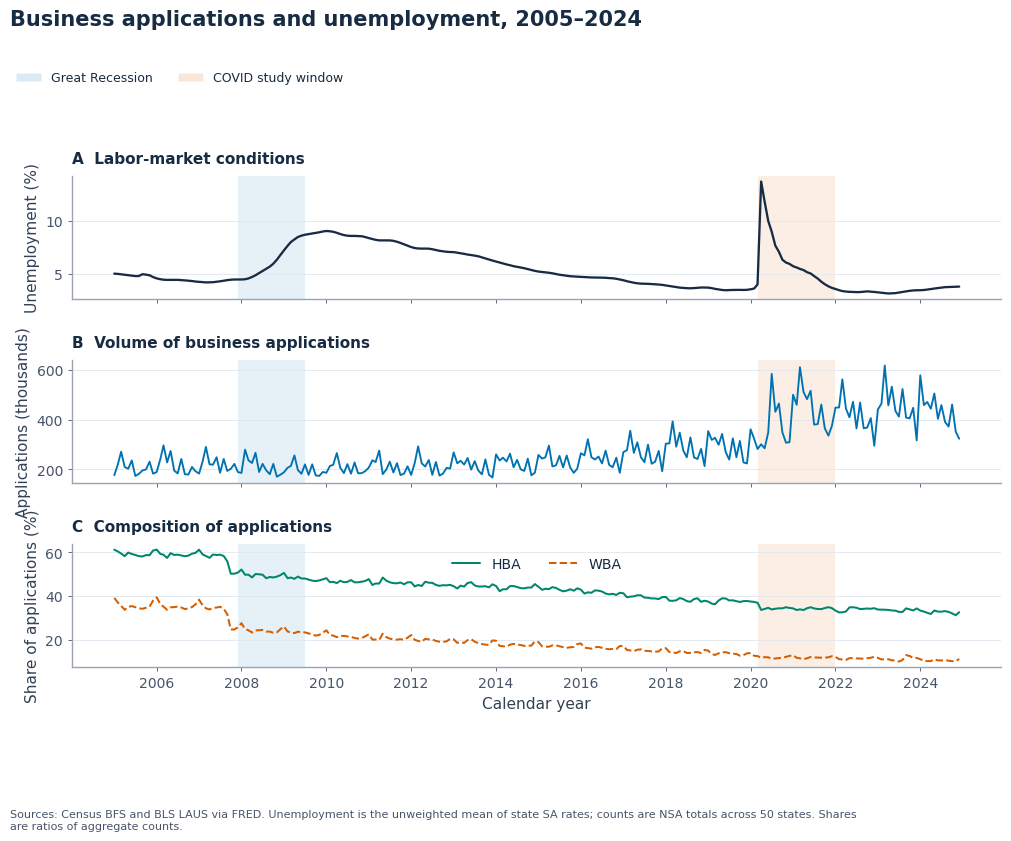

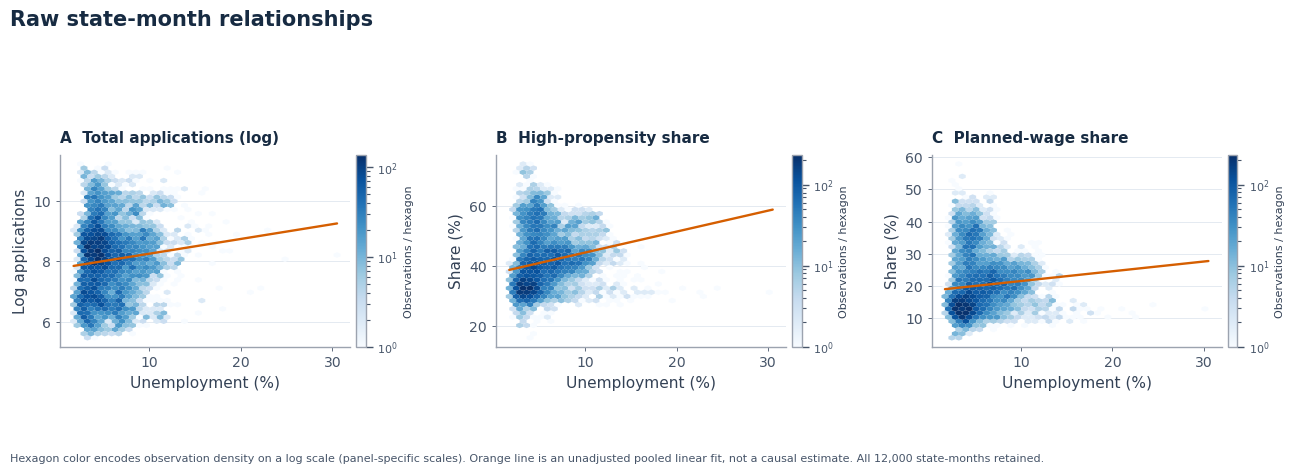

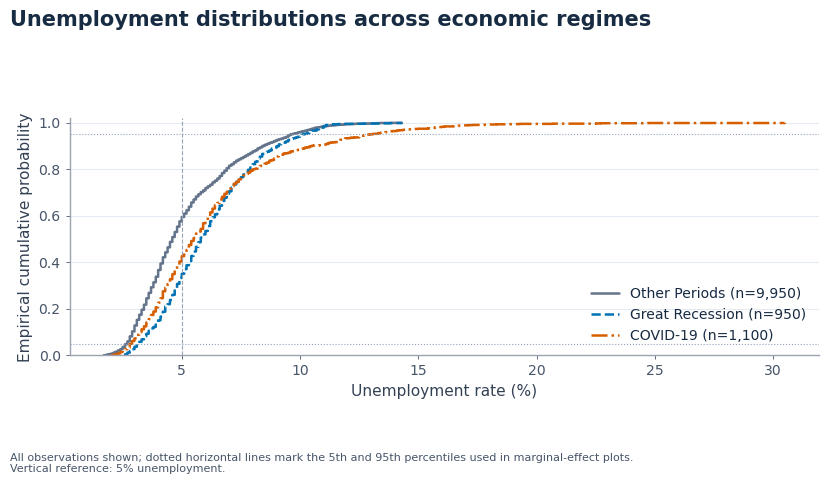

In [7]:
monthly = df.groupby("date").agg(BA=("BA","sum"), HBA=("HBA","sum"), WBA=("WBA","sum"), UR=("UR_SA","mean"))
fig, axes=plt.subplots(3,1,figsize=(10.5,8.5),sharex=True)
axes[0].plot(monthly.index,monthly.UR,color=INK,lw=1.65); axes[0].set_ylabel("Unemployment (%)")
axes[1].plot(monthly.index,monthly.BA,color=BLUE,lw=1.35); axes[1].set_ylabel("Applications (thousands)")
axes[1].yaxis.set_major_formatter(FuncFormatter(lambda x,p:f"{x/1000:,.0f}"))
for v,c,ls in [("HBA",TEAL,"-"),("WBA",ORANGE,"--")]:
    axes[2].plot(monthly.index,100*monthly[v]/monthly.BA,label=v,color=c,ls=ls,lw=1.45)
axes[2].set_ylabel("Share of applications (%)"); axes[2].legend(frameon=False,ncol=2,loc="best")
for ax,letter,title in zip(axes,"ABC",["Labor-market conditions","Volume of business applications","Composition of applications"]):
    panel_title(ax,letter,title); finish_axes(ax)
    for window,c in [(GFC,BLUE),(COVID,ORANGE)]:
        ax.axvspan(pd.Timestamp(window[0]),pd.Timestamp(window[1])+pd.offsets.MonthEnd(0),color=c,alpha=.10,lw=0,zorder=0)
axes[-1].xaxis.set_major_locator(YearLocator(2)); axes[-1].xaxis.set_major_formatter(DateFormatter("%Y"))
axes[-1].set_xlabel("Calendar year")
legend=[Patch(facecolor=BLUE,alpha=.15,label="Great Recession"),Patch(facecolor=ORANGE,alpha=.15,label="COVID study window")]
save_fig(fig,"figure01_historical_trends","Business applications and unemployment, 2005–2024",
         "Sources: Census BFS and BLS LAUS via FRED. Unemployment is the unweighted mean of state SA rates; counts are NSA totals across 50 states. Shares are ratios of aggregate counts.",legend=legend,top=.88)

fig,axes=plt.subplots(1,3,figsize=(13.5,4.7))
for ax,letter,(y,title) in zip(axes,"ABC",OUTCOMES):
    h=ax.hexbin(df.UR_SA,df[y],gridsize=38,mincnt=1,norm=LogNorm(),cmap="Blues",linewidths=0,rasterized=True)
    x=np.linspace(df.UR_SA.min(),df.UR_SA.max(),150); b,a=np.polyfit(df.UR_SA,df[y],1)
    ax.plot(x,a+b*x,color=ORANGE,lw=1.7,label="Pooled linear fit")
    ax.set(xlabel="Unemployment (%)",ylabel="Log applications" if y=="log_ba" else "Share (%)")
    panel_title(ax,letter,OUTCOME_LABEL[y]); finish_axes(ax)
    cb=fig.colorbar(h,ax=ax,pad=.02,fraction=.045); cb.set_label("Observations / hexagon",fontsize=8); cb.ax.tick_params(labelsize=8)
save_fig(fig,"figure02_bivariate","Raw state-month relationships",
         "Hexagon color encodes observation density on a log scale (panel-specific scales). Orange line is an unadjusted pooled linear fit, not a causal estimate. All 12,000 state-months retained.",top=.84)

# Distribution/support diagnostic; no regression results used.
fig,ax=plt.subplots(figsize=(8.6,4.8))
for i,regime in enumerate(REGIMES):
    z=df.loc[df.regime.eq(regime),"UR_SA"].sort_values().to_numpy()
    c,ls=REGIME_STYLE[regime]; ax.step(z,np.arange(1,len(z)+1)/len(z),where="post",color=c,ls=ls,lw=1.8,label=f"{regime} (n={len(z):,})")
ax.axhline(.05,color="#94A3B8",lw=.8,ls=":"); ax.axhline(.95,color="#94A3B8",lw=.8,ls=":")
ax.axvline(CENTER,color="#94A3B8",lw=.8,ls="--"); ax.set(xlabel="Unemployment rate (%)",ylabel="Empirical cumulative probability",ylim=(0,1.02)); finish_axes(ax); ax.legend(frameon=False,loc="lower right")
save_fig(fig,"figure02b_unemployment_support","Unemployment distributions across economic regimes",
         "All observations shown; dotted horizontal lines mark the 5th and 95th percentiles used in marginal-effect plots. Vertical reference: 5% unemployment.",top=.87)


## 5. Model and inference utilities
All specifications use state-clustered covariance unless explicitly labeled two-way clustered. For scalar contrasts use a cluster-t reference with G−1 degrees of freedom; for joint restrictions use an approximate cluster-robust F(q,G−1) reference (Wald chi-square divided by q). With two-way clustering use the smaller cluster dimension for reference degrees of freedom. This is a finite-cluster approximation, not an exact finite-sample test. `linearmodels` covariance defaults are explicit below; p-values may differ from V1. Do not compare pooled and within R² as if identical. All models are unweighted.

In [8]:
M1, M2, M3, M4, M5, M6 = "M1 Pooled OLS", "M2 State FE", "M3 TWFE", "M4 Quadratic", "M5 Crisis interaction", "M6 Combined"
FEATURES = ["sa_c", "sa_sq", "sa_gfc", "sa_covid"]
SPECS = {M1:["UR_SA"], M2:["UR_SA"], M3:["UR_SA"], M4:["sa_c","sa_sq"],
         M5:["sa_c","sa_gfc","sa_covid"], M6:FEATURES}
fit_log = []

def fit_model(data, y, features, effects="twfe", two_way=False, trends=False, label=""):
    # Always explicit data, never a bound default panel. No silent missing rows.
    required = [y,*features]
    if not np.isfinite(data[required].to_numpy(dtype=float)).all():
        raise ValueError(f"Nonfinite values in {label}/{y}; define sample explicitly")
    if effects not in {"pooled", "state", "twfe", "seasonal"}:
        raise ValueError(f"Unknown fixed-effect specification: {effects}")
    p = data.set_index(["state","date"]).sort_index()
    assert p.index.is_unique
    X = p[features].astype(float).copy()
    if trends:
        # All but one state slope; common trend is already absorbed by time FE.
        if effects != "twfe": raise ValueError("Trends require TWFE")
        states = sorted(p.index.get_level_values(0).unique())
        for s in states[1:]: X[f"trend_{s}"] = (p.index.get_level_values(0)==s)*p.time_years.to_numpy()
    X = sm.add_constant(X, has_constant="add")
    if effects == "pooled": model = PooledOLS(p[y],X)
    elif effects == "seasonal":
        season = pd.DataFrame({"season":pd.Categorical(p.state_season).codes},index=p.index)
        model = PanelOLS(p[y],X,time_effects=True,other_effects=season)
    else:
        model = PanelOLS(p[y],X,entity_effects=True,time_effects=effects=="twfe")
    res = model.fit(cov_type="clustered",cluster_entity=True,cluster_time=two_way,
                    debiased=True,group_debias=False)
    g = min(p.index.get_level_values(0).nunique(),p.index.get_level_values(1).nunique()) if two_way else p.index.get_level_values(0).nunique()
    fit_log.append(dict(label=label,outcome=y,N=res.nobs,states=p.index.get_level_values(0).nunique(),
                        months=p.index.get_level_values(1).nunique(),effects=effects,cluster="state+month" if two_way else "state",trends=trends,R2_model=res.rsquared))
    return res, int(g-1)

def contrast(fit, weights):
    res, dof = fit
    L = pd.Series(0.,index=res.params.index)
    for name, weight in weights.items():
        if name not in L.index: raise KeyError(name)
        L[name]=weight
    est=float(L @ res.params); var=float(L @ res.cov @ L)
    if not np.isfinite(var) or var <= 0:
        warnings.warn(f"Invalid contrast variance {var}; inference unavailable")
        return dict(Estimate=est,SE=np.nan,P_value=np.nan,CI_lower=np.nan,CI_upper=np.nan,DF=dof)
    se=np.sqrt(var); critical=t.ppf(.975,dof)
    return dict(Estimate=est,SE=se,P_value=2*t.sf(abs(est/se),dof),CI_lower=est-critical*se,CI_upper=est+critical*se,DF=dof)

def joint_test(fit, restrictions):
    res,dof=fit; R=pd.DataFrame(0.,index=range(len(restrictions)),columns=res.params.index)
    for i, weights in enumerate(restrictions):
        for k,v in weights.items():
            if k not in res.params.index: raise KeyError(k)
            R.loc[i,k]=v
    z=R.to_numpy() @ res.params.to_numpy(); V=R.to_numpy() @ res.cov.to_numpy() @ R.to_numpy().T
    q=len(restrictions)
    if not np.isfinite(V).all() or np.min(np.linalg.eigvalsh((V+V.T)/2))<=0:
        warnings.warn("Invalid restriction covariance; joint inference unavailable")
        return dict(F_stat=np.nan,P_value=np.nan,DF1=q,DF2=dof)
    stat=float(z @ np.linalg.solve(V,z))/q
    return dict(F_stat=stat,P_value=f.sf(stat,q,dof),DF1=q,DF2=dof)

def coef_rows(fit,y,label,features):
    return [dict(Outcome=y,Model=label,Variable=k,N=fit[0].nobs,**contrast(fit,{k:1})) for k in features]

## 6. Baseline models: pooled OLS, state FE, two-way FE

,Outcome,Model,Variable,N,Estimate,SE,P_value,CI_lower,CI_upper,DF
0,log_ba,M1 Pooled OLS,UR_SA,12000,0.04876,0.03170,0.13045,-0.01495,0.11247,49
1,log_ba,M2 State FE,UR_SA,12000,-0.06161,0.00520,0.00000,-0.07206,-0.05116,49
2,log_ba,M3 TWFE,UR_SA,12000,-0.00155,0.01011,0.87868,-0.02186,0.01876,49
3,hba_share,M1 Pooled OLS,UR_SA,12000,0.69622,0.10632,0.00000,0.48257,0.90987,49
4,hba_share,M2 State FE,UR_SA,12000,0.73556,0.09819,0.00000,0.53824,0.93289,49
5,hba_share,M3 TWFE,UR_SA,12000,-0.23985,0.09884,0.01896,-0.43847,-0.04123,49
6,wba_share,M1 Pooled OLS,UR_SA,12000,0.30386,0.12416,0.01802,0.05435,0.55337,49
7,wba_share,M2 State FE,UR_SA,12000,0.58334,0.09685,0.00000,0.38872,0.77797,49
8,wba_share,M3 TWFE,UR_SA,12000,-0.15380,0.10819,0.16150,-0.37121,0.06362,49


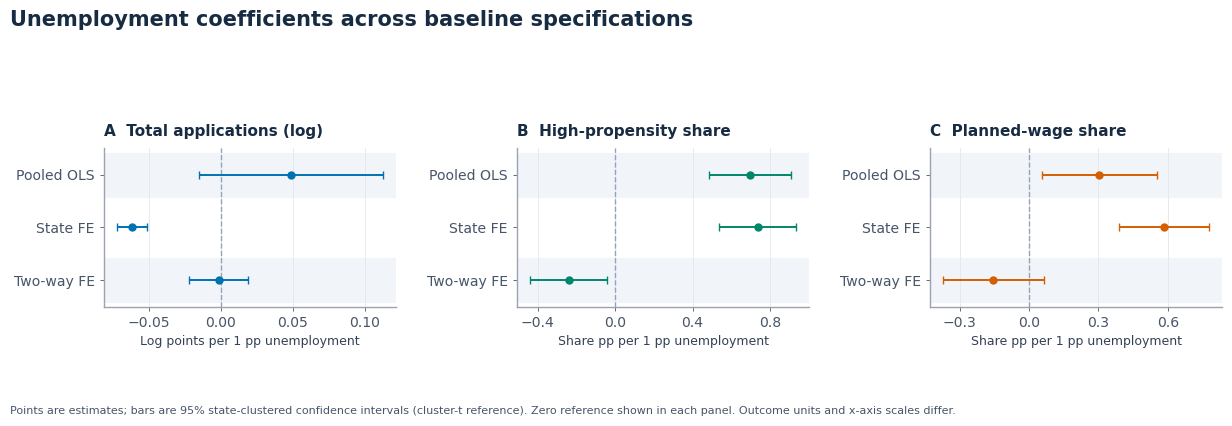

,Outcome,Model,Variable,N,Estimate,SE,P_value,CI_lower,CI_upper,DF,V1_Estimate,V1_SE,Estimate_difference,SE_difference,Matches_V1_rounding,Matches_V1_SE_rounding,Matches_V1_both
0,log_ba,M1 Pooled OLS,UR_SA,12000,0.04876,0.03170,0.13045,-0.01495,0.11247,49,0.0488,0.0317,-0.00004,0.00000,True,True,True
1,log_ba,M2 State FE,UR_SA,12000,-0.06161,0.00520,0.00000,-0.07206,-0.05116,49,-0.0616,0.0052,-0.00001,0.00000,True,True,True
2,log_ba,M3 TWFE,UR_SA,12000,-0.00155,0.01011,0.87868,-0.02186,0.01876,49,-0.0016,0.0101,0.00005,0.00001,True,True,True
3,hba_share,M1 Pooled OLS,UR_SA,12000,0.69622,0.10632,0.00000,0.48257,0.90987,49,0.6962,0.1063,0.00002,0.00002,True,True,True
4,hba_share,M2 State FE,UR_SA,12000,0.73556,0.09819,0.00000,0.53824,0.93289,49,0.7356,0.0982,-0.00004,-0.00001,True,True,True
5,hba_share,M3 TWFE,UR_SA,12000,-0.23985,0.09884,0.01896,-0.43847,-0.04123,49,-0.2399,0.0988,0.00005,0.00004,True,True,True
6,wba_share,M1 Pooled OLS,UR_SA,12000,0.30386,0.12416,0.01802,0.05435,0.55337,49,0.3039,0.1242,-0.00004,-0.00004,True,True,True
7,wba_share,M2 State FE,UR_SA,12000,0.58334,0.09685,0.00000,0.38872,0.77797,49,0.5833,0.0969,0.00004,-0.00005,True,True,True
8,wba_share,M3 TWFE,UR_SA,12000,-0.15380,0.10819,0.16150,-0.37121,0.06362,49,-0.1538,0.1082,0.00000,-0.00001,True,True,True


All nine baseline coefficients and SEs agree with V1 to reported precision.


In [9]:
models={}; rows=[]
for y in Y_VARS:
    for name,effects in [(M1,"pooled"),(M2,"state"),(M3,"twfe")]:
        fit=fit_model(df,y,SPECS[name],effects=effects,label=name)
        models[y,name]=fit; rows.extend(coef_rows(fit,y,name,SPECS[name]))
baseline_table=pd.DataFrame(rows)
save_table(baseline_table,"table03_baseline")
fig,axes=plt.subplots(1,3,figsize=(12.8,4.2))
for ax,letter,(y,title) in zip(axes,"ABC",OUTCOMES):
    z=baseline_table[baseline_table.Outcome.eq(y)].set_index("Model").loc[[M1,M2,M3]].reset_index()
    forest(ax,z,["Pooled OLS","State FE","Two-way FE"],OUTCOME_COLOR[y]); panel_title(ax,letter,OUTCOME_LABEL[y]); ax.set_xlabel(SLOPE_UNIT[y],fontsize=9)
save_fig(fig,"figure03_baseline_coefficients","Unemployment coefficients across baseline specifications",
         "Points are estimates; bars are 95% state-clustered confidence intervals (cluster-t reference). Zero reference shown in each panel. Outcome units and x-axis scales differ.",top=.84)

# Compare with rounded estimates saved in the original V1 notebook.
V1_REFERENCE = [{'Outcome': 'log_ba', 'Model': 'Pooled OLS', 'Coefficient': 0.0488, 'Std_Error': 0.0317}, {'Outcome': 'log_ba', 'Model': 'State FE', 'Coefficient': -0.0616, 'Std_Error': 0.0052}, {'Outcome': 'log_ba', 'Model': 'TWFE', 'Coefficient': -0.0016, 'Std_Error': 0.0101}, {'Outcome': 'hba_share', 'Model': 'Pooled OLS', 'Coefficient': 0.6962, 'Std_Error': 0.1063}, {'Outcome': 'hba_share', 'Model': 'State FE', 'Coefficient': 0.7356, 'Std_Error': 0.0982}, {'Outcome': 'hba_share', 'Model': 'TWFE', 'Coefficient': -0.2399, 'Std_Error': 0.0988}, {'Outcome': 'wba_share', 'Model': 'Pooled OLS', 'Coefficient': 0.3039, 'Std_Error': 0.1242}, {'Outcome': 'wba_share', 'Model': 'State FE', 'Coefficient': 0.5833, 'Std_Error': 0.0969}, {'Outcome': 'wba_share', 'Model': 'TWFE', 'Coefficient': -0.1538, 'Std_Error': 0.1082}]
v1=pd.DataFrame(V1_REFERENCE).rename(columns={"Coefficient":"V1_Estimate","Std_Error":"V1_SE"})
v1["Model"]=v1.Model.map({"Pooled OLS":M1,"State FE":M2,"TWFE":M3})
comparison=baseline_table.merge(v1,on=["Outcome","Model"],validate="one_to_one")
comparison["Estimate_difference"]=comparison.Estimate-comparison.V1_Estimate
assert len(comparison) == len(baseline_table) == len(v1) == 9
comparison["SE_difference"] = comparison.SE - comparison.V1_SE
# V1 reference values were reported rounded to four decimal places.
comparison["Matches_V1_rounding"] = comparison.Estimate_difference.abs() <= 0.000051
comparison["Matches_V1_SE_rounding"] = comparison.SE_difference.abs() <= 0.000051
comparison["Matches_V1_both"] = comparison.Matches_V1_rounding & comparison.Matches_V1_SE_rounding
save_table(comparison,"diagnostic_v1_baseline_comparison")
if not comparison.Matches_V1_both.all():
    warnings.warn("V1 coefficient or SE mismatch: investigate data vintage, package version and covariance specification; do not assume equivalence.")
else:
    print("All nine baseline coefficients and SEs agree with V1 to reported precision.")

## 7. Extended models: quadratic and crisis interactions
M4 permits curvature; M5 allows crisis-specific slopes; M6 combines these with common curvature. The pure time dummies are absorbed by year-month fixed effects. The centering point is 5 percentage points.

In [10]:
rows=[]
for y in Y_VARS:
    for name in [M4,M5,M6]:
        fit=fit_model(df,y,SPECS[name],label=name)
        models[y,name]=fit; rows.extend(coef_rows(fit,y,name,SPECS[name]))
extended_table=pd.DataFrame(rows)
save_table(extended_table,"table04_extended")

,Outcome,Model,Variable,N,Estimate,SE,P_value,CI_lower,CI_upper,DF
0,log_ba,M4 Quadratic,sa_c,12000,0.00036,0.01669,0.98292,-0.03318,0.03389,49
1,log_ba,M4 Quadratic,sa_sq,12000,-0.00025,0.00090,0.78508,-0.00206,0.00156,49
2,log_ba,M5 Crisis interaction,sa_c,12000,-0.00506,0.01340,0.70741,-0.03200,0.02188,49
3,log_ba,M5 Crisis interaction,sa_gfc,12000,0.01486,0.00641,0.02467,0.00198,0.02774,49
4,log_ba,M5 Crisis interaction,sa_covid,12000,0.00712,0.01455,0.62668,-0.02212,0.03637,49
5,log_ba,M6 Combined,sa_c,12000,-0.00224,0.01705,0.89581,-0.03650,0.03201,49
6,log_ba,M6 Combined,sa_sq,12000,-0.00048,0.00079,0.54748,-0.00208,0.00112,49
7,log_ba,M6 Combined,sa_gfc,12000,0.01484,0.00637,0.02394,0.00204,0.02764,49
8,log_ba,M6 Combined,sa_covid,12000,0.01009,0.01323,0.44914,-0.01649,0.03667,49
9,hba_share,M4 Quadratic,sa_c,12000,-0.43474,0.14792,0.00501,-0.73199,-0.13749,49


## 8. Statistical inference: contrasts, multiplicity, and support
Holm adjustment is applied to the three cross-crisis slope tests as one family; a second, separately labeled adjustment covers all nine M6 tests. All are exploratory unless the student can document a pre-results specification. Confidence intervals are pointwise, not simultaneous.

In [11]:
rows=[]
for y in Y_VARS:
    fit=models[y,M6]
    for label, restrictions in {"Joint crisis interactions":[{"sa_gfc":1},{"sa_covid":1}],
        "COVID minus GFC":[{"sa_covid":1,"sa_gfc":-1}], "Quadratic":[{"sa_sq":1}]}.items():
        rows.append(dict(Outcome=y,Test=label,**joint_test(fit,restrictions)))
wald_table=pd.DataFrame(rows)
wald_table["Holm_all_9"]=np.nan; wald_table["Holm_crisis_family"]=np.nan
for mask,col in [(wald_table.P_value.notna(),"Holm_all_9"),
    (wald_table.Test.eq("COVID minus GFC") & wald_table.P_value.notna(),"Holm_crisis_family")]:
    # Missing tests still count toward the family size (conservative p=1 placeholder).
    family=wald_table if col=="Holm_all_9" else wald_table[wald_table.Test.eq("COVID minus GFC")]
    adjusted=pd.Series(multipletests(family.P_value.fillna(1),method="holm")[1],index=family.index)
    wald_table.loc[mask,col]=adjusted.loc[mask]
save_table(wald_table,"table05_wald_holm")

,Outcome,Test,F_stat,P_value,DF1,DF2,Holm_all_9,Holm_crisis_family
0,log_ba,Joint crisis interactions,3.39589,0.04157,2,49,0.29102,NaN
1,log_ba,COVID minus GFC,0.09279,0.76195,1,49,1.00000,0.96578
2,log_ba,Quadratic,0.36693,0.54748,1,49,1.00000,NaN
3,hba_share,Joint crisis interactions,0.71415,0.49463,2,49,1.00000,NaN
4,hba_share,COVID minus GFC,0.49990,0.48289,1,49,1.00000,0.96578
5,hba_share,Quadratic,11.68018,0.00128,1,49,0.01152,NaN
6,wba_share,Joint crisis interactions,3.22675,0.04826,2,49,0.29102,NaN
7,wba_share,COVID minus GFC,4.72213,0.03464,1,49,0.27712,0.10392
8,wba_share,Quadratic,0.25894,0.61313,1,49,1.00000,NaN


,Min,P05,Median,P95,Max
regime,,,,,
COVID-19,2.0,2.9,5.5,12.905,30.5
Great Recession,2.6,3.2,5.8,10.100,14.3
Other Periods,1.7,2.7,4.6,9.600,14.3


,Outcome,Regime,UR,Central_support,Estimate,SE,P_value,CI_lower,CI_upper,DF
0,log_ba,Other Periods,3,True,-0.00032,0.01977,0.98719,-0.04005,0.03941,49
1,log_ba,Other Periods,5,True,-0.00224,0.01705,0.89581,-0.03650,0.03201,49
2,log_ba,Other Periods,8,True,-0.00513,0.01334,0.70225,-0.03195,0.02168,49
3,log_ba,Other Periods,10,False,-0.00706,0.01133,0.53622,-0.02982,0.01571,49
4,log_ba,Great Recession,3,False,0.01452,0.02132,0.49888,-0.02832,0.05737,49
5,log_ba,Great Recession,5,True,0.01260,0.01885,0.50696,-0.02528,0.05048,49
6,log_ba,Great Recession,8,True,0.00971,0.01563,0.53719,-0.02170,0.04112,49
7,log_ba,Great Recession,10,True,0.00779,0.01398,0.58010,-0.02031,0.03589,49
8,log_ba,COVID-19,3,True,0.00977,0.01783,0.58614,-0.02606,0.04560,49
9,log_ba,COVID-19,5,True,0.00785,0.01489,0.60059,-0.02208,0.03777,49


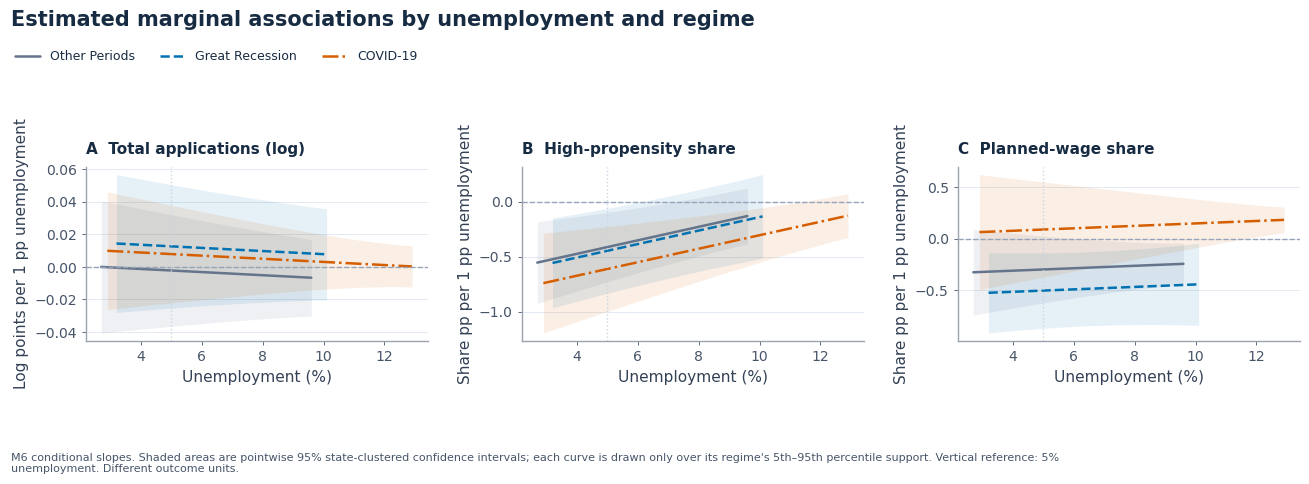

In [12]:
support=df.groupby("regime").UR_SA.agg(Min="min",P05=lambda x:x.quantile(.05),Median="median",P95=lambda x:x.quantile(.95),Max="max")
save_table(support,"diagnostic_support",index=True)

def me(fit,ur,regime):
    w={"sa_c":1,"sa_sq":2*(ur-CENTER)}
    if regime=="Great Recession":w["sa_gfc"]=1
    if regime=="COVID-19":w["sa_covid"]=1
    return contrast(fit,w)
rows=[]
for y in Y_VARS:
    for regime in REGIMES:
        for ur in [3,5,8,10]:
            rows.append(dict(Outcome=y,Regime=regime,UR=ur,Central_support=support.loc[regime,"P05"]<=ur<=support.loc[regime,"P95"],**me(models[y,M6],ur,regime)))
marginal_table=pd.DataFrame(rows)
save_table(marginal_table,"table06_marginal_effects")
fig,axes=plt.subplots(1,3,figsize=(13.6,4.8),sharex=True)
for ax,letter,(y,title) in zip(axes,"ABC",OUTCOMES):
    for regime in REGIMES:
        color,ls=REGIME_STYLE[regime]
        grid=np.linspace(support.loc[regime,"P05"],support.loc[regime,"P95"],100)
        z=pd.DataFrame([me(models[y,M6],u,regime) for u in grid])
        ax.plot(grid,z.Estimate.to_numpy(float),color=color,ls=ls,lw=1.8)
        ax.fill_between(grid,z.CI_lower.to_numpy(float),z.CI_upper.to_numpy(float),color=color,alpha=.10,linewidth=0)
    ax.axhline(0,ls="--",color="#94A3B8",lw=1); ax.axvline(CENTER,color="#CBD5E1",ls=":",lw=1)
    ax.set(xlabel="Unemployment (%)",ylabel=SLOPE_UNIT[y]); panel_title(ax,letter,OUTCOME_LABEL[y]); finish_axes(ax)
legend=[Line2D([0],[0],color=REGIME_STYLE[r][0],ls=REGIME_STYLE[r][1],lw=1.8,label=r) for r in REGIMES]
save_fig(fig,"figure04_marginal_effects","Estimated marginal associations by unemployment and regime",
         "M6 conditional slopes. Shaded areas are pointwise 95% state-clustered confidence intervals; each curve is drawn only over its regime's 5th–95th percentile support. Vertical reference: 5% unemployment. Different outcome units.",legend=legend,top=.82,bottom=.17)


In [13]:
# Turning point plus slope at both endpoints; no automatic U-shape claim.
rows=[]; fit=models["hba_share",M6]; b=fit[0].params
for regime in REGIMES:
    shift={"Other Periods":0,"Great Recession":b.sa_gfc,"COVID-19":b.sa_covid}[regime]
    turn=CENTER-(b.sa_c+shift)/(2*b.sa_sq) if abs(b.sa_sq)>1e-12 else np.nan
    lo,hi=support.loc[regime,["P05","P95"]]
    left,right=me(fit,lo,regime),me(fit,hi,regime)
    rows.append(dict(Regime=regime,Turning_point=turn,P05=lo,P95=hi,Inside_central_support=lo<=turn<=hi,
        Left_slope=left["Estimate"],Left_CI_upper=left["CI_upper"],Right_slope=right["Estimate"],Right_CI_lower=right["CI_lower"]))
save_table(pd.DataFrame(rows),"diagnostic_turning_points")

,Regime,Turning_point,P05,P95,Inside_central_support,Left_slope,Left_CI_upper,Right_slope,Right_CI_lower
0,Other Periods,11.73580,2.7,9.600,False,-0.55449,-0.18305,-0.13107,-0.38519
1,Great Recession,12.28992,3.2,10.100,False,-0.55782,-0.14924,-0.13439,-0.51454
2,COVID-19,14.97787,2.9,12.905,False,-0.74118,-0.28803,-0.12720,-0.32666


## 9. Exploratory extension: outcome decomposition
Compare log counts of each category and its complement, using a common positive-count sample within each family. Also estimate log share and log total on that same sample. The log-share coefficient must equal the category log-count coefficient minus the total log-count coefficient (same design and sample). This is an algebraic decomposition, not evidence of individual transitions or motivations.

In [14]:
rows=[]; identities=[]
for family in ["hba","wba"]:
    ys=[f"log_{family}",f"log_non_{family}","log_ba",f"log_{family}_share"]
    sample=df.dropna(subset=ys).copy()
    print(f"{family}: common sample {len(sample):,} of {len(df):,}")
    for spec in [M3,M6]:
        fits={y:fit_model(sample,y,SPECS[spec],label=f"decomposition {family} {spec}") for y in ys}
        for y,fit in fits.items():
            rows.extend(dict(Family=family,**r) for r in coef_rows(fit,y,spec,SPECS[spec]))
        for term in SPECS[spec]:
            direct=fits[ys[3]][0].params[term]
            diff=fits[ys[0]][0].params[term]-fits["log_ba"][0].params[term]
            assert np.isclose(direct,diff,atol=1e-8,rtol=1e-7), (family,spec,term,direct,diff)
            identities.append(dict(Family=family,Model=spec,Variable=term,Direct=direct,Count_minus_total=diff,N=len(sample)))
decomp_table=pd.DataFrame(rows)
save_table(decomp_table,"table07_decomposition")
save_table(pd.DataFrame(identities),"diagnostic_decomposition_identity")

hba: common sample 12,000 of 12,000
wba: common sample 12,000 of 12,000


,Family,Outcome,Model,Variable,N,Estimate,SE,P_value,CI_lower,CI_upper,DF
0,hba,log_hba,M3 TWFE,UR_SA,12000,-0.00738,0.00875,0.40281,-0.02497,0.01020,49
1,hba,log_non_hba,M3 TWFE,UR_SA,12000,0.00348,0.01071,0.74676,-0.01804,0.02500,49
2,hba,log_ba,M3 TWFE,UR_SA,12000,-0.00155,0.01011,0.87868,-0.02186,0.01876,49
3,hba,log_hba_share,M3 TWFE,UR_SA,12000,-0.00583,0.00290,0.04951,-0.01165,-0.00001,49
4,hba,log_hba,M6 Combined,sa_c,12000,-0.01205,0.01477,0.41842,-0.04174,0.01763,49
5,hba,log_hba,M6 Combined,sa_sq,12000,0.00021,0.00072,0.77415,-0.00124,0.00165,49
6,hba,log_hba,M6 Combined,sa_gfc,12000,0.01250,0.00626,0.05123,-0.00007,0.02508,49
7,hba,log_hba,M6 Combined,sa_covid,12000,0.00637,0.01284,0.62187,-0.01942,0.03217,49
8,hba,log_non_hba,M6 Combined,sa_c,12000,0.00646,0.01837,0.72663,-0.03046,0.04338,49
9,hba,log_non_hba,M6 Combined,sa_sq,12000,-0.00110,0.00088,0.21680,-0.00288,0.00067,49


,Family,Model,Variable,Direct,Count_minus_total,N
0,hba,M3 TWFE,UR_SA,-0.00583,-0.00583,12000
1,hba,M6 Combined,sa_c,-0.00981,-0.00981,12000
2,hba,M6 Combined,sa_sq,0.00069,0.00069,12000
3,hba,M6 Combined,sa_gfc,-0.00234,-0.00234,12000
4,hba,M6 Combined,sa_covid,-0.00372,-0.00372,12000
5,wba,M3 TWFE,UR_SA,-0.01288,-0.01288,12000
6,wba,M6 Combined,sa_c,-0.02398,-0.02398,12000
7,wba,M6 Combined,sa_sq,0.00117,0.00117,12000
8,wba,M6 Combined,sa_gfc,-0.00477,-0.00477,12000
9,wba,M6 Combined,sa_covid,0.00807,0.00807,12000


### 9.1 Exploratory extension: nested application composition (V2.3)

The Census Bureau defines high-propensity business applications (HBA) as a subset of business applications (BA), and planned-wage applications (WBA) as a subset of HBA. See [BFS definitions](https://www.census.gov/econ/bfs/definitions.html) and [BFS methodology](https://www.census.gov/econ/bfs/technicaldocumentation/methodology.html). Check that the downloaded state-month counts actually satisfy this ordering before analysis.

For strictly positive counts, the identity is

$$\log(WBA/BA)=\log(HBA/BA)+\log(WBA/HBA).$$

The third ratio measures the prevalence of a reported planned first wage date **among HBA applications**, not an individual transition probability or realized hiring. Estimate all three log ratios on exactly the same sample and with the same M3 and M6 regressors and fixed effects. OLS linearity implies the coefficient identity term by term (and for linear contrasts). Estimate the conditional ratio directly for its own clustered standard error and confidence interval; subtracting standard errors is invalid.

This is a post-results exploratory extension. Do not treat it as an independent confirmatory test or add its tests to the existing pre-labeled nine-test family. Report any new tests as unadjusted exploratory inference. Census classification can change across vintages; a violation of the nesting in the observed counts blocks this extension, rather than being silently discarded. The original outcomes are retained regardless of significance.


In [15]:
# V2.3: nested composition; no changes to the original models or inference family.
nested_outcomes = ["log_wba_share", "log_hba_share", "log_wba_given_hba"]
nested_counts = ["BA", "HBA", "WBA"]
nested_bad = df.loc[~df.nested_valid, ["state", "date", *nested_counts]]
save_table(nested_bad, "diagnostic_nested_order_violations")
positive = (df[nested_counts] > 0).all(axis=1)
finite = np.isfinite(df[nested_outcomes].to_numpy(dtype=float)).all(axis=1)
nested_sample = df.loc[df.nested_valid & positive & finite].copy()
nested_diagnostic = pd.DataFrame([dict(
    Total=len(df), Ordering_violations=len(nested_bad), Nonpositive_counts=int((~positive).sum()),
    Eligible=len(nested_sample), Excluded=len(df)-len(nested_sample),
    States=nested_sample.state.nunique(), Months=nested_sample.date.nunique())])
save_table(nested_diagnostic, "diagnostic_nested_sample")
nested_table = pd.DataFrame(columns=["Outcome","Model","Variable","N","Estimate","SE","P_value","CI_lower","CI_upper","DF"])
nested_identity_table = pd.DataFrame(columns=["Model","Contrast","Total_log_share","HBA_log_share","Within_HBA_log_share","Sum_components","Difference","N"])
nested_fits = {}
if not nested_bad.empty:
    warnings.warn("Observed counts violate WBA <= HBA <= BA. Nested extension skipped; inspect diagnostic and FRED vintage.")
elif nested_sample.empty or nested_sample.state.nunique() < 2:
    warnings.warn("No suitable common sample for nested extension; skipped.")
else:
    assert np.allclose(nested_sample.log_wba_share,
                       nested_sample.log_hba_share + nested_sample.log_wba_given_hba,
                       atol=1e-10, rtol=0)
    rows, identity_rows = [], []
    for spec in [M3, M6]:
        fits = {y: fit_model(nested_sample, y, SPECS[spec], label=f"nested composition {spec}")
                for y in nested_outcomes}
        nested_fits.update({(y, spec): fit for y, fit in fits.items()})
        assert all(fit[0].nobs == len(nested_sample) for fit in fits.values())
        for y, fit in fits.items():
            rows.extend(coef_rows(fit, y, spec, SPECS[spec]))
        tests = {term: {term: 1} for term in SPECS[spec]}
        if spec == M6:
            tests.update({"ME at 5% | GFC": {"sa_c": 1, "sa_gfc": 1},
                          "ME at 5% | COVID": {"sa_c": 1, "sa_covid": 1},
                          "COVID minus GFC": {"sa_covid": 1, "sa_gfc": -1}})
        for label, weights in tests.items():
            a,b,c = [contrast(fits[y], weights)["Estimate"] for y in nested_outcomes]
            assert np.isclose(a, b+c, atol=1e-8, rtol=1e-7), (spec,label,a,b,c)
            identity_rows.append(dict(Model=spec, Contrast=label, Total_log_share=a,
                HBA_log_share=b, Within_HBA_log_share=c, Sum_components=b+c,
                Difference=a-b-c, N=len(nested_sample)))
    nested_table = pd.DataFrame(rows)
    nested_identity_table = pd.DataFrame(identity_rows)
    # Report exact percent change in the ratio for a 1 pp UR increase under M3.
    # The log ratio identity applies to log slopes, not exponentiated effects.
    nested_m3 = nested_table.loc[nested_table.Model.eq(M3)].copy()
    for col, source in [("Pct_change", "Estimate"), ("Pct_CI_lower", "CI_lower"), ("Pct_CI_upper", "CI_upper")]:
        nested_m3[col] = 100 * np.expm1(nested_m3[source])
    save_table(nested_m3, "table_nested_m3_percent_change")
    print("Nested identity verified for all terms and selected M6 contrasts.")
    print("All p-values in this exploratory extension are unadjusted.")
save_table(nested_table, "table_nested_composition")
save_table(nested_identity_table, "diagnostic_nested_coefficient_identity")


,state,date,BA,HBA,WBA


,Total,Ordering_violations,Nonpositive_counts,Eligible,Excluded,States,Months
0,12000,0,0,12000,0,50,240


,Outcome,Model,Variable,N,Estimate,SE,P_value,CI_lower,CI_upper,DF,Pct_change,Pct_CI_lower,Pct_CI_upper
0,log_wba_share,M3 TWFE,UR_SA,12000,-0.01288,0.00633,0.04743,-0.02560,-0.00015,49,-1.27948,-2.52780,-0.01517
1,log_hba_share,M3 TWFE,UR_SA,12000,-0.00583,0.00290,0.04951,-0.01165,-0.00001,49,-0.58168,-1.15867,-0.00131
2,log_wba_given_hba,M3 TWFE,UR_SA,12000,-0.00704,0.00435,0.11151,-0.01578,0.00169,49,-0.70188,-1.56538,0.16918


Nested identity verified for all terms and selected M6 contrasts.
All p-values in this exploratory extension are unadjusted.


,Outcome,Model,Variable,N,Estimate,SE,P_value,CI_lower,CI_upper,DF
0,log_wba_share,M3 TWFE,UR_SA,12000,-0.01288,0.00633,0.04743,-0.02560,-0.00015,49
1,log_hba_share,M3 TWFE,UR_SA,12000,-0.00583,0.00290,0.04951,-0.01165,-0.00001,49
2,log_wba_given_hba,M3 TWFE,UR_SA,12000,-0.00704,0.00435,0.11151,-0.01578,0.00169,49
3,log_wba_share,M6 Combined,sa_c,12000,-0.02398,0.00999,0.02027,-0.04406,-0.00390,49
4,log_wba_share,M6 Combined,sa_sq,12000,0.00117,0.00068,0.09137,-0.00020,0.00254,49
5,log_wba_share,M6 Combined,sa_gfc,12000,-0.00477,0.00511,0.35523,-0.01503,0.00550,49
6,log_wba_share,M6 Combined,sa_covid,12000,0.00807,0.00998,0.42262,-0.01199,0.02813,49
7,log_hba_share,M6 Combined,sa_c,12000,-0.00981,0.00449,0.03372,-0.01883,-0.00079,49
8,log_hba_share,M6 Combined,sa_sq,12000,0.00069,0.00023,0.00473,0.00022,0.00116,49
9,log_hba_share,M6 Combined,sa_gfc,12000,-0.00234,0.00306,0.44812,-0.00849,0.00381,49


,Model,Contrast,Total_log_share,HBA_log_share,Within_HBA_log_share,Sum_components,Difference,N
0,M3 TWFE,UR_SA,-0.01288,-0.00583,-0.00704,-0.01288,-0.0,12000
1,M6 Combined,sa_c,-0.02398,-0.00981,-0.01417,-0.02398,-0.0,12000
2,M6 Combined,sa_sq,0.00117,0.00069,0.00049,0.00117,0.0,12000
3,M6 Combined,sa_gfc,-0.00477,-0.00234,-0.00243,-0.00477,-0.0,12000
4,M6 Combined,sa_covid,0.00807,-0.00372,0.01179,0.00807,-0.0,12000
5,M6 Combined,ME at 5% | GFC,-0.02875,-0.01215,-0.01660,-0.02875,-0.0,12000
6,M6 Combined,ME at 5% | COVID,-0.01591,-0.01353,-0.00238,-0.01591,-0.0,12000
7,M6 Combined,COVID minus GFC,0.01284,-0.00138,0.01422,0.01284,-0.0,12000


## 10. Robustness and sensitivity
Retain all V1 checks. State-by-calendar-month FE subsumes state FE. The NSA comparison uses the same seasonality specification as the SA comparison. Lagged UR is indexed by the outcome month's crisis regime. State-specific trends are exploratory and remove differential linear trends, not all time-varying confounders.

In [16]:
def key_contrasts(prefix="sa", covid="covid"):
    return {"ME at 5% (other periods)":{f"{prefix}_c":1},"Quadratic":{f"{prefix}_sq":1},
            "COVID minus GFC":{f"{prefix}_{covid}":1,f"{prefix}_gfc":-1}}
robustness_models={}; rows=[]
for y in Y_VARS:
    specs=[("Original M6",df,FEATURES,{},"sa","covid"),
        ("Two-way clustering",df,FEATURES,dict(two_way=True),"sa","covid"),
        ("State seasonality (SA)",df,FEATURES,dict(effects="seasonal"),"sa","covid"),
        ("UR <= 15%",df[df.UR_SA<=15],FEATURES,{},"sa","covid"),
        ("Short COVID window",df,["sa_c","sa_sq","sa_gfc","sa_covid_short"],{},"sa","covid_short"),
        ("Lagged unemployment",df.dropna(subset=["UR_LAG"]),["lag_c","lag_sq","lag_gfc","lag_covid"],{},"lag","covid"),
        ("State seasonality (NSA)",df,["nsa_c","nsa_sq","nsa_gfc","nsa_covid"],dict(effects="seasonal"),"nsa","covid"),
        ("State-specific trends",df,FEATURES,dict(trends=True),"sa","covid")]
    for label,sample,features,kwargs,prefix,window in specs:
        fit=models[y,M6] if label=="Original M6" else fit_model(sample,y,features,label=label,**kwargs)
        robustness_models[y,label]=fit
        if label=="Two-way clustering": np.testing.assert_allclose(fit[0].params,models[y,M6][0].params,atol=1e-9)
        for test,w in key_contrasts(prefix,window).items():
            rows.append(dict(Outcome=y,Specification=label,Test=test,N=fit[0].nobs,**contrast(fit,w)))
robustness_table=pd.DataFrame(rows)
save_table(robustness_table,"table08_robustness")

,Outcome,Specification,Test,N,Estimate,SE,P_value,CI_lower,CI_upper,DF
0,log_ba,Original M6,ME at 5% (other periods),12000,-0.00224,0.01705,0.89581,-0.03650,0.03201,49
1,log_ba,Original M6,Quadratic,12000,-0.00048,0.00079,0.54748,-0.00208,0.00112,49
2,log_ba,Original M6,COVID minus GFC,12000,-0.00475,0.01560,0.76195,-0.03611,0.02660,49
3,log_ba,Two-way clustering,ME at 5% (other periods),12000,-0.00224,0.01709,0.89610,-0.03660,0.03211,49
4,log_ba,Two-way clustering,Quadratic,12000,-0.00048,0.00080,0.54841,-0.00208,0.00112,49
...,...,...,...,...,...,...,...,...,...,...
67,wba_share,State seasonality (NSA),Quadratic,12000,0.00639,0.01166,0.58615,-0.01704,0.02981,49
68,wba_share,State seasonality (NSA),COVID minus GFC,12000,0.54466,0.26516,0.04532,0.01181,1.07751,49
69,wba_share,State-specific trends,ME at 5% (other periods),12000,-0.39889,0.11802,0.00143,-0.63606,-0.16172,49
70,wba_share,State-specific trends,Quadratic,12000,0.02265,0.00658,0.00119,0.00943,0.03587,49


In [17]:
# Population-normalized outcome (same sample), plus a conditional population control.
rows=[]
for spec in [M3,M6]:
    for name,y,features in [("Original", "log_ba", SPECS[spec]),
                            ("Per 100k population", "log_ba_per_100k", SPECS[spec]),
                            ("Control log population", "log_ba", SPECS[spec]+["log_population"])]:
        fit=models[y,spec] if name=="Original" else fit_model(df,y,features,label=name+" "+spec)
        rows.extend(dict(Specification=name,**r) for r in coef_rows(fit,y,spec,features))
population_table=pd.DataFrame(rows)
save_table(population_table,"table09_population")
# Comparable quadratic regressions, including historical window and COVID exclusions.
rows=[]
for y in Y_VARS:
    for name,sample in [("Full sample",df),("Exclude acute COVID",df[~df.date.between(*COVID_ACUTE)]),
                        ("Exclude COVID period",df[df.covid.eq(0)]),("2012–2024",df[df.year>=2012])]:
        fit=models[y,M4] if name=="Full sample" else fit_model(sample,y,SPECS[M4],label=name)
        rows.extend(dict(Sample=name,**r) for r in coef_rows(fit,y,M4,SPECS[M4]))
exclusion_table=pd.DataFrame(rows)
save_table(exclusion_table,"table10_sample_sensitivity")

,Specification,Outcome,Model,Variable,N,Estimate,SE,P_value,CI_lower,CI_upper,DF
0,Original,log_ba,M3 TWFE,UR_SA,12000,-0.00155,0.01011,0.87868,-0.02186,0.01876,49
1,Per 100k population,log_ba_per_100k,M3 TWFE,UR_SA,12000,-0.00210,0.01005,0.83529,-0.02230,0.01810,49
2,Control log population,log_ba,M3 TWFE,UR_SA,12000,-0.00197,0.01007,0.84544,-0.02221,0.01827,49
3,Control log population,log_ba,M3 TWFE,log_population,12000,0.76804,0.33535,0.02635,0.09413,1.44194,49
4,Original,log_ba,M6 Combined,sa_c,12000,-0.00224,0.01705,0.89581,-0.03650,0.03201,49
5,Original,log_ba,M6 Combined,sa_sq,12000,-0.00048,0.00079,0.54748,-0.00208,0.00112,49
6,Original,log_ba,M6 Combined,sa_gfc,12000,0.01484,0.00637,0.02394,0.00204,0.02764,49
7,Original,log_ba,M6 Combined,sa_covid,12000,0.01009,0.01323,0.44914,-0.01649,0.03667,49
8,Per 100k population,log_ba_per_100k,M6 Combined,sa_c,12000,-0.00337,0.01707,0.84419,-0.03768,0.03094,49
9,Per 100k population,log_ba_per_100k,M6 Combined,sa_sq,12000,-0.00048,0.00078,0.54214,-0.00204,0.00109,49


,Sample,Outcome,Model,Variable,N,Estimate,SE,P_value,CI_lower,CI_upper,DF
0,Full sample,log_ba,M4 Quadratic,sa_c,12000,0.00036,0.01669,0.98292,-0.03318,0.03389,49
1,Full sample,log_ba,M4 Quadratic,sa_sq,12000,-0.00025,0.00090,0.78508,-0.00206,0.00156,49
2,Exclude acute COVID,log_ba,M4 Quadratic,sa_c,11850,-0.00023,0.01945,0.99055,-0.03932,0.03886,49
3,Exclude acute COVID,log_ba,M4 Quadratic,sa_sq,11850,0.00001,0.00153,0.99672,-0.00306,0.00308,49
4,Exclude COVID period,log_ba,M4 Quadratic,sa_c,10900,0.00356,0.02083,0.86500,-0.03830,0.04542,49
5,Exclude COVID period,log_ba,M4 Quadratic,sa_sq,10900,0.00001,0.00164,0.99525,-0.00329,0.00331,49
6,2012–2024,log_ba,M4 Quadratic,sa_c,7800,-0.00932,0.01397,0.50757,-0.03739,0.01874,49
7,2012–2024,log_ba,M4 Quadratic,sa_sq,7800,0.00044,0.00061,0.46802,-0.00078,0.00166,49
8,Full sample,hba_share,M4 Quadratic,sa_c,12000,-0.43474,0.14792,0.00501,-0.73199,-0.13749,49
9,Full sample,hba_share,M4 Quadratic,sa_sq,12000,0.02521,0.00796,0.00266,0.00921,0.04121,49


### 10.1 Optional exploratory economic controls
Compare controlled and uncontrolled M6 on exactly the same permit-available sample. Permit activity and population can be endogenous or affected by economic conditions, so this is a conditional association check, not an identification strategy. Missing/invalid permits are not imputed. If coverage is inadequate (under 90% or any state absent), skip visibly.

In [18]:
control_rows=[]
(OUT / "diagnostic_optional_controls_error.txt").unlink(missing_ok=True)
sample=df.dropna(subset=["log1p_permits"]).copy()
if RUN_ECONOMIC_CONTROLS and len(sample)>=.90*len(df) and sample.state.nunique()==len(STATES):
    try:
        for y in Y_VARS:
            for label,features in [("Matched M6",FEATURES),("M6 + population + permits",FEATURES+["log_population","log1p_permits"])]:
                fit=fit_model(sample,y,features,label=label)
                control_rows.extend(coef_rows(fit,y,label,features))
        controls_status=f"Estimated on {len(sample):,} state-months"
    except Exception as exc:
        # This boundary is restricted to the optional model block; core errors still raise.
        # Includes absorbed regressors, rank deficiency and numerical failures.
        control_rows=[]
        controls_status=f"Optional estimation failed; no partial comparison reported: {type(exc).__name__}: {exc}"
        (OUT / "diagnostic_optional_controls_error.txt").write_text(traceback.format_exc(), encoding="utf-8")
        warnings.warn(controls_status)
else:
    controls_status=f"Skipped: {controls_status}; usable rows={len(sample)}"
print(controls_status)
control_table=pd.DataFrame(control_rows,columns=["Outcome","Model","Variable","N","Estimate","SE","P_value","CI_lower","CI_upper","DF"])
save_table(control_table,"table11_optional_controls")

Estimated on 12,000 state-months


,Outcome,Model,Variable,N,Estimate,SE,P_value,CI_lower,CI_upper,DF
0,log_ba,Matched M6,sa_c,12000,-0.00224,0.01705,0.89581,-0.03650,0.03201,49
1,log_ba,Matched M6,sa_sq,12000,-0.00048,0.00079,0.54748,-0.00208,0.00112,49
2,log_ba,Matched M6,sa_gfc,12000,0.01484,0.00637,0.02394,0.00204,0.02764,49
3,log_ba,Matched M6,sa_covid,12000,0.01009,0.01323,0.44914,-0.01649,0.03667,49
4,log_ba,M6 + population + permits,sa_c,12000,0.00040,0.01599,0.98019,-0.03174,0.03254,49
5,log_ba,M6 + population + permits,sa_sq,12000,-0.00052,0.00076,0.50127,-0.00205,0.00102,49
6,log_ba,M6 + population + permits,sa_gfc,12000,0.01211,0.00638,0.06358,-0.00071,0.02493,49
7,log_ba,M6 + population + permits,sa_covid,12000,0.01057,0.01450,0.46957,-0.01857,0.03971,49
8,log_ba,M6 + population + permits,log_population,12000,0.68138,0.34355,0.05294,-0.00900,1.37176,49
9,log_ba,M6 + population + permits,log1p_permits,12000,0.03251,0.02315,0.16649,-0.01401,0.07903,49


## 11. Report-ready tables and figures
All results are generated from fitted objects, not manually copied. Stars use the same cluster-t convention. Export both numeric tables and formatted HTML tables; use only a concise subset in the 10-page report. Do not selectively omit nonsignificant estimates.

Figures use an accessible palette, explicit units, pointwise intervals and PDF vector export (dense hexagons are rasterized). Separate outcome-specific robustness and sample-sensitivity plots preserve readable labels. Use the baseline, marginal effects, and one focused diagnostic as report candidates; the rest are supporting evidence. The figure catalogue provides titles and notes.

log_ba baseline


,M1 Pooled OLS,M2 State FE,M3 TWFE
Unemployment rate,0.0488,-0.0616***,-0.0016
Unemployment rate (SE),(0.0317),(0.0052),(0.0101)
State FE,No,Yes,Yes
Year-month FE,No,No,Yes
Observations,"12,000","12,000","12,000"
Cluster reference df,49,49,49


log_ba extended


,M4 Quadratic,M5 Crisis interaction,M6 Combined
UR centered at 5%,0.0004,-0.0051,-0.0022
UR centered at 5% (SE),(0.0167),(0.0134),(0.0170)
Centered UR squared,-0.0002,—,-0.0005
Centered UR squared (SE),(0.0009),—,(0.0008)
Centered UR × GFC,—,0.0149**,0.0148**
Centered UR × GFC (SE),—,(0.0064),(0.0064)
Centered UR × COVID,—,0.0071,0.0101
Centered UR × COVID (SE),—,(0.0146),(0.0132)
State FE,Yes,Yes,Yes
Year-month FE,Yes,Yes,Yes


hba_share baseline


,M1 Pooled OLS,M2 State FE,M3 TWFE
Unemployment rate,0.6962***,0.7356***,-0.2399**
Unemployment rate (SE),(0.1063),(0.0982),(0.0988)
State FE,No,Yes,Yes
Year-month FE,No,No,Yes
Observations,"12,000","12,000","12,000"
Cluster reference df,49,49,49


... (2 outputs left out)

wba_share baseline


,M1 Pooled OLS,M2 State FE,M3 TWFE
Unemployment rate,0.3039**,0.5833***,-0.1538
Unemployment rate (SE),(0.1242),(0.0969),(0.1082)
State FE,No,Yes,Yes
Year-month FE,No,No,Yes
Observations,"12,000","12,000","12,000"
Cluster reference df,49,49,49


wba_share extended


,M4 Quadratic,M5 Crisis interaction,M6 Combined
UR centered at 5%,-0.2892*,-0.2647**,-0.2995*
UR centered at 5% (SE),(0.1640),(0.1164),(0.1617)
Centered UR squared,0.0175*,—,0.0059
Centered UR squared (SE),(0.0095),—,(0.0117)
Centered UR × GFC,—,-0.2053,-0.2051
Centered UR × GFC (SE),—,(0.1495),(0.1489)
Centered UR × COVID,—,0.4246***,0.3880**
Centered UR × COVID (SE),—,(0.1265),(0.1536)
State FE,Yes,Yes,Yes
Year-month FE,Yes,Yes,Yes


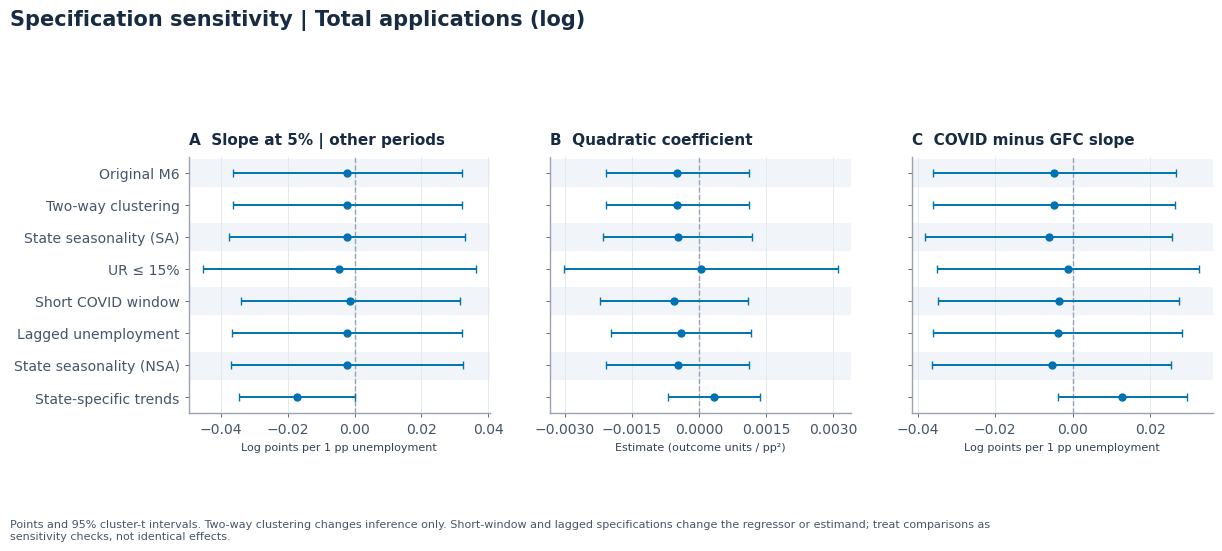

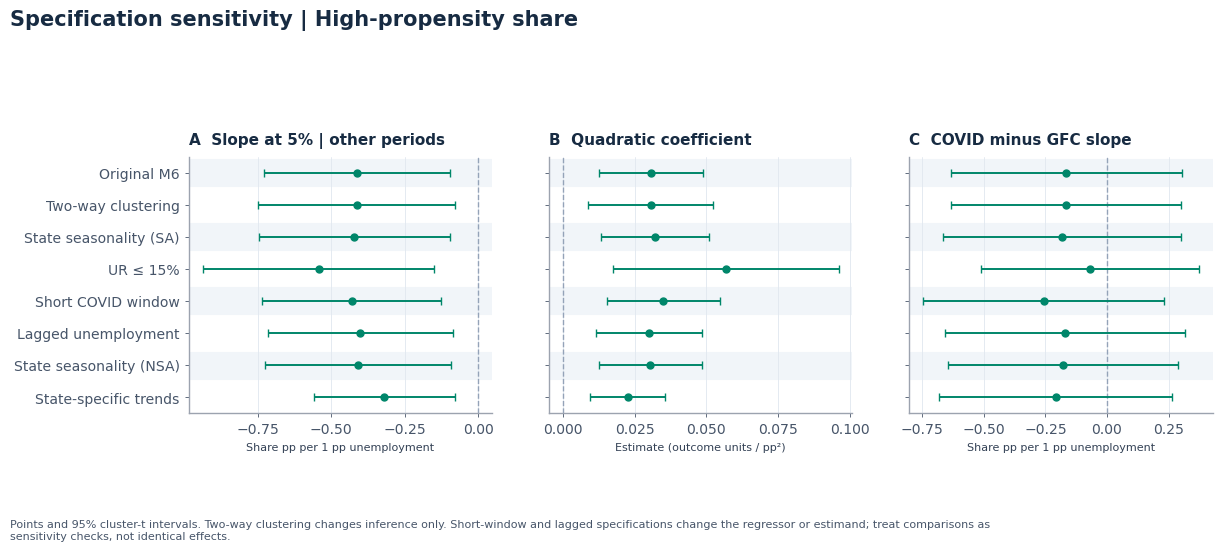

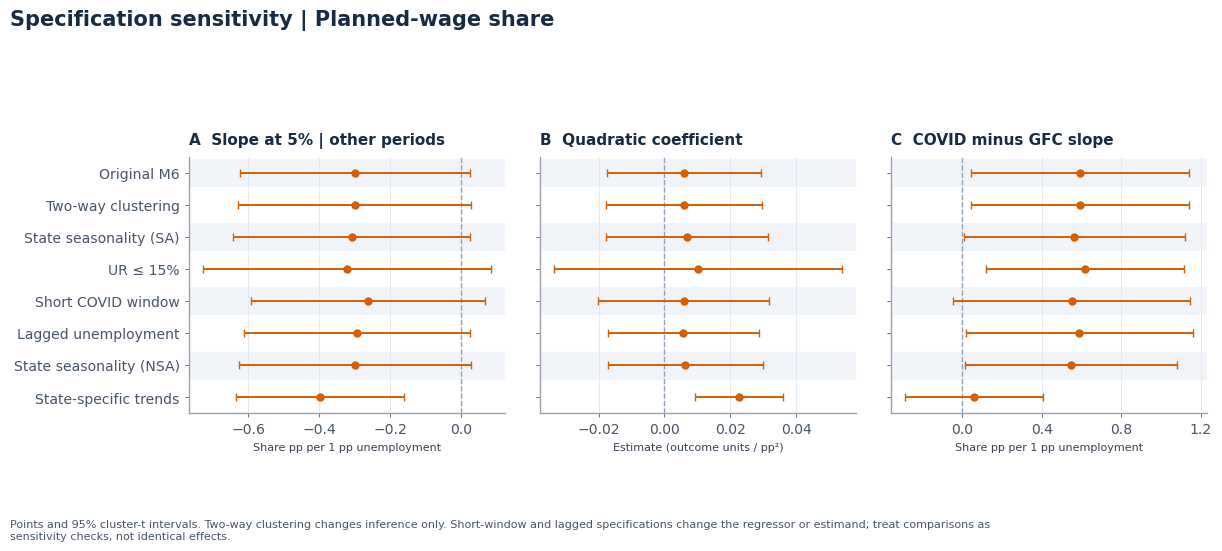

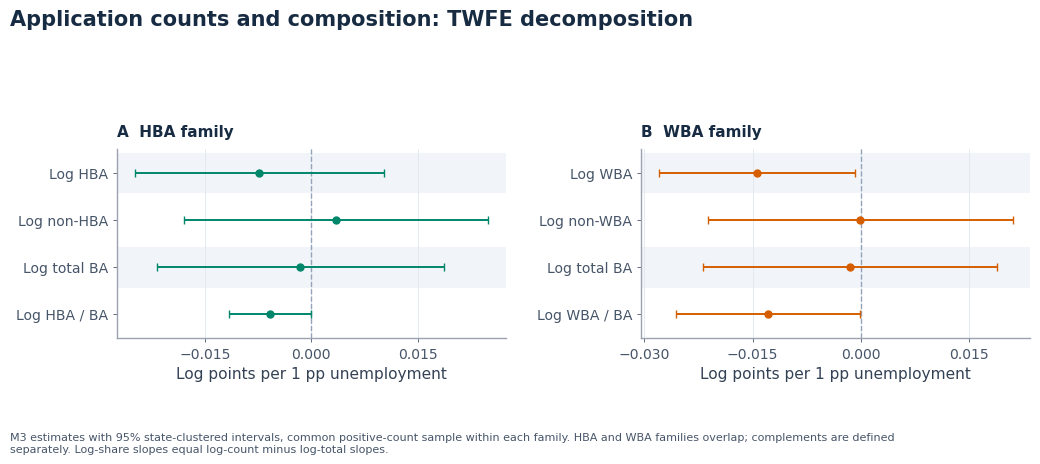

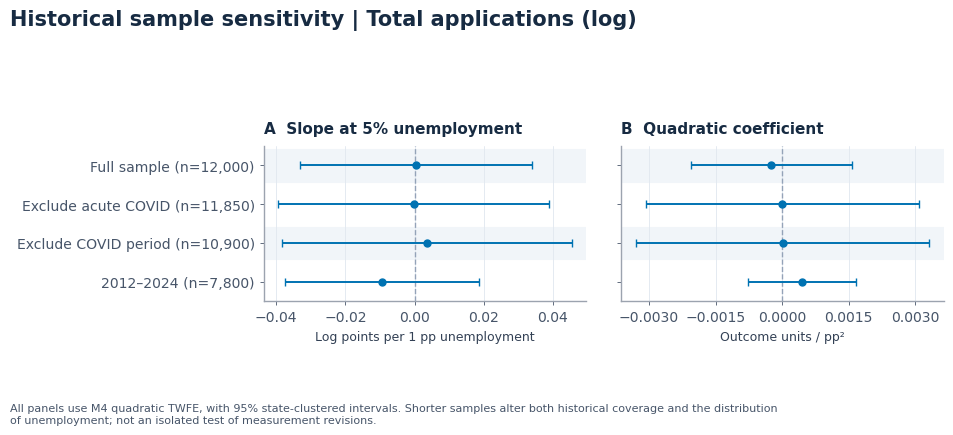

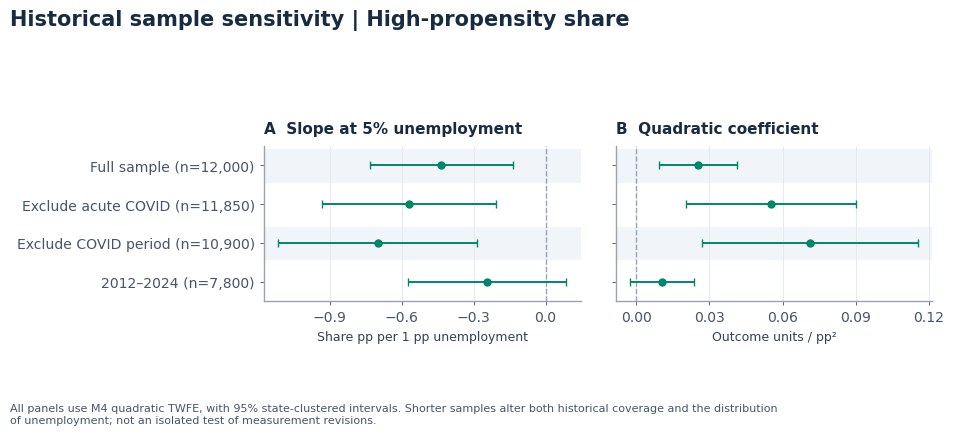

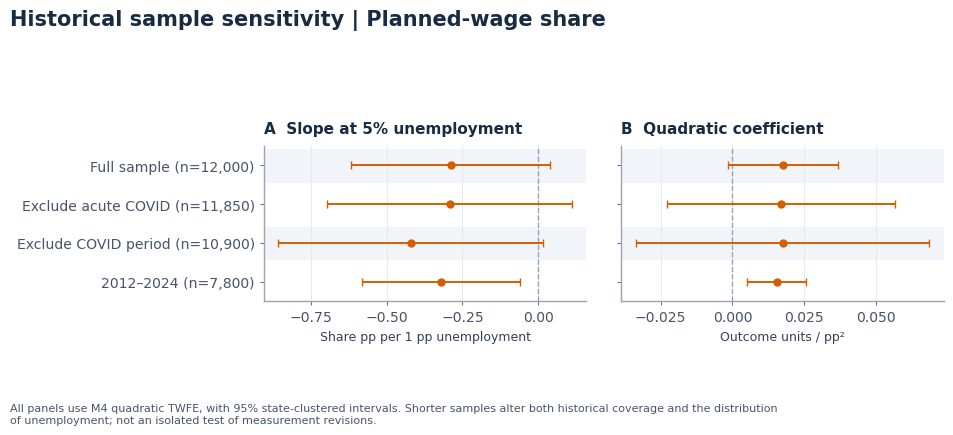

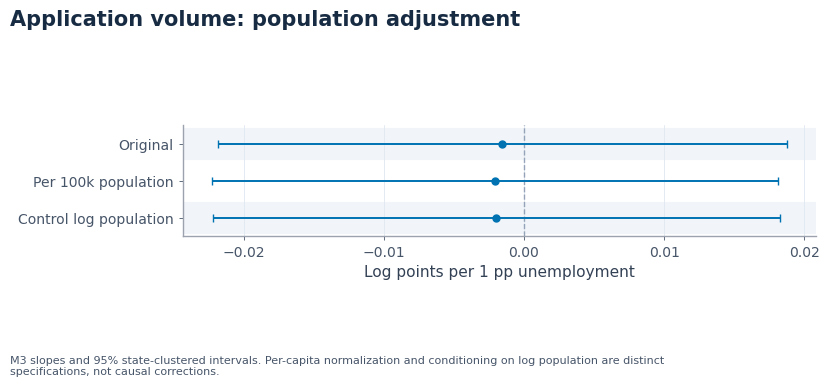

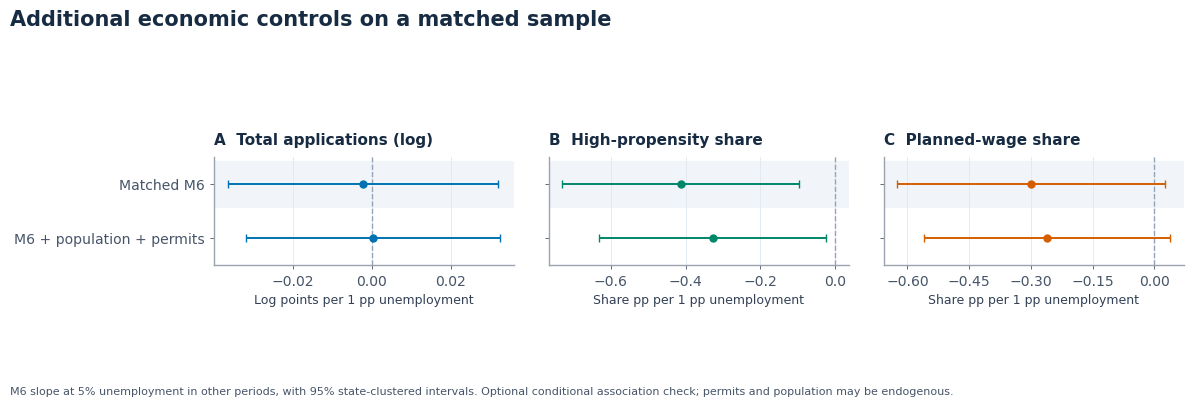

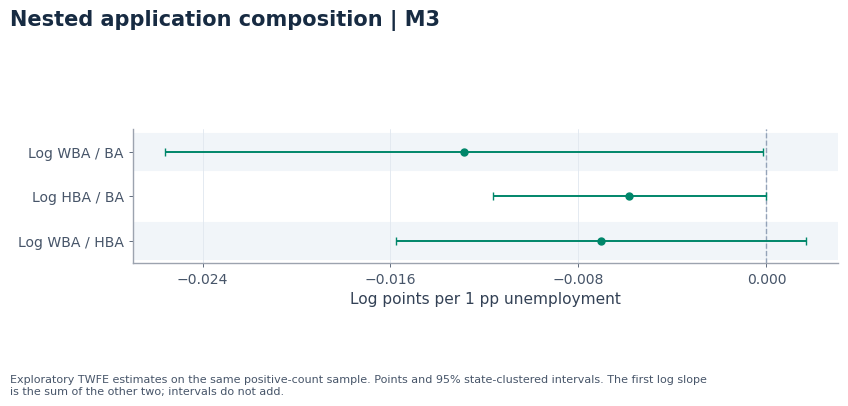

In [19]:
def stars(p): return "***" if p<.01 else "**" if p<.05 else "*" if p<.10 else ""
def formatted_table(y,names):
    records={}
    labels={"UR_SA":"Unemployment rate","sa_c":"UR centered at 5%","sa_sq":"Centered UR squared","sa_gfc":"Centered UR × GFC","sa_covid":"Centered UR × COVID"}
    terms=list(dict.fromkeys(k for name in names for k in SPECS[name]))
    for name in names:
        fit=models[y,name]; col={}
        for term in terms:
            if term in SPECS[name]:
                z=contrast(fit,{term:1})
                col[labels[term]]=f'{z["Estimate"]:.4f}{stars(z["P_value"])}' if np.isfinite(z["Estimate"]) else "—"
                col[labels[term]+" (SE)"]=f'({z["SE"]:.4f})' if np.isfinite(z["SE"]) else "NA"
            else:
                col[labels[term]]=col[labels[term]+" (SE)"]="—"
        col.update({"State FE":"No" if name==M1 else "Yes","Year-month FE":"No" if name in [M1,M2] else "Yes",
                    "Observations":f"{fit[0].nobs:,}","Cluster reference df":str(fit[1])})
        records[name]=col
    return pd.DataFrame(records)
for y in Y_VARS:
    for tag,names in [("baseline",[M1,M2,M3]),("extended",[M4,M5,M6])]:
        table=formatted_table(y,names)
        table.to_csv(OUT/f"report_{y}_{tag}.csv")
        (OUT/f"report_{y}_{tag}.html").write_text(table.to_html()+"<p>State-clustered SE in parentheses. * p &lt; .10; ** p &lt; .05; *** p &lt; .01 (cluster-t reference). Unweighted state-months.</p>")
        print(y,tag); display(table)
# One readable robustness figure per outcome (rather than a crowded 3 x 3 grid).
TEST_LABELS={"ME at 5% (other periods)":"Slope at 5% | other periods", "Quadratic":"Quadratic coefficient", "COVID minus GFC":"COVID minus GFC slope"}
ROBUST_LABELS={"Original M6":"Original M6","Two-way clustering":"Two-way clustering","State seasonality (SA)":"State seasonality (SA)","UR <= 15%":"UR ≤ 15%","Short COVID window":"Short COVID window","Lagged unemployment":"Lagged unemployment","State seasonality (NSA)":"State seasonality (NSA)","State-specific trends":"State-specific trends"}
for y in Y_VARS:
    fig,axes=plt.subplots(1,3,figsize=(12.7,5.5))
    for ax,letter,test in zip(axes,"ABC",key_contrasts()):
        z=robustness_table[(robustness_table.Outcome==y)&(robustness_table.Test==test)].copy()
        forest(ax,z,[ROBUST_LABELS.get(v,v) for v in z.Specification],OUTCOME_COLOR[y]); panel_title(ax,letter,TEST_LABELS[test]); ax.set_xlabel("Estimate (outcome units / pp²)" if test=="Quadratic" else SLOPE_UNIT[y],fontsize=8)
        if letter!="A": ax.tick_params(axis="y",labelleft=False)
    save_fig(fig,f"figure05_robustness_{y}",f"Specification sensitivity | {OUTCOME_LABEL[y]}",
        "Points and 95% cluster-t intervals. Two-way clustering changes inference only. Short-window and lagged specifications change the regressor or estimand; treat comparisons as sensitivity checks, not identical effects.",top=.86,bottom=.15)

# Decomposition: comparable slopes from M3, same sample within each family.
fig,axes=plt.subplots(1,2,figsize=(10.8,4.6))
for ax,letter,family in zip(axes,"AB",["hba","wba"]):
    ys=[f"log_{family}",f"log_non_{family}","log_ba",f"log_{family}_share"]
    z=decomp_table[(decomp_table.Family==family)&(decomp_table.Model==M3)&(decomp_table.Variable=="UR_SA")].set_index("Outcome").loc[ys].reset_index()
    forest(ax,z,[f"Log {family.upper()}",f"Log non-{family.upper()}","Log total BA",f"Log {family.upper()} / BA"],TEAL if family=="hba" else ORANGE)
    panel_title(ax,letter,f"{family.upper()} family"); ax.set_xlabel("Log points per 1 pp unemployment")
save_fig(fig,"figure06_decomposition","Application counts and composition: TWFE decomposition",
         "M3 estimates with 95% state-clustered intervals, common positive-count sample within each family. HBA and WBA families overlap; complements are defined separately. Log-share slopes equal log-count minus log-total slopes.",top=.85)

# Sample-window comparison uses exactly the same M4 specification.
for y in Y_VARS:
    fig,axes=plt.subplots(1,2,figsize=(9.9,4.3))
    for ax,letter,term,title in zip(axes,"AB",["sa_c","sa_sq"],["Slope at 5% unemployment","Quadratic coefficient"]):
        z=exclusion_table[(exclusion_table.Outcome==y)&(exclusion_table.Variable==term)]
        forest(ax,z,[f"{r.Sample} (n={r.N:,})" for r in z.itertuples()],OUTCOME_COLOR[y]); panel_title(ax,letter,title)
        ax.set_xlabel(SLOPE_UNIT[y] if term=="sa_c" else "Outcome units / pp²",fontsize=9)
        if letter=="B":ax.tick_params(axis="y",labelleft=False)
    save_fig(fig,f"figure07_sample_sensitivity_{y}",f"Historical sample sensitivity | {OUTCOME_LABEL[y]}",
        "All panels use M4 quadratic TWFE, with 95% state-clustered intervals. Shorter samples alter both historical coverage and the distribution of unemployment; not an isolated test of measurement revisions.",top=.85,bottom=.17)

fig,ax=plt.subplots(figsize=(8.6,3.8))
z=population_table[(population_table.Model==M3)&(population_table.Variable=="UR_SA")]
forest(ax,z,z.Specification.tolist(),BLUE); ax.set_xlabel("Log points per 1 pp unemployment")
save_fig(fig,"figure08_population_sensitivity","Application volume: population adjustment",
         "M3 slopes and 95% state-clustered intervals. Per-capita normalization and conditioning on log population are distinct specifications, not causal corrections.",top=.82,bottom=.23)

if not control_table.empty:
    fig,axes=plt.subplots(1,3,figsize=(12.4,4.0))
    for ax,letter,y in zip(axes,"ABC",Y_VARS):
        z=control_table[(control_table.Outcome==y)&(control_table.Variable=="sa_c")]
        forest(ax,z,z.Model.tolist(),OUTCOME_COLOR[y]); panel_title(ax,letter,OUTCOME_LABEL[y]); ax.set_xlabel(SLOPE_UNIT[y],fontsize=9)
        if letter!="A":ax.tick_params(axis="y",labelleft=False)
    save_fig(fig,"figure09_optional_controls","Additional economic controls on a matched sample",
        "M6 slope at 5% unemployment in other periods, with 95% state-clustered intervals. Optional conditional association check; permits and population may be endogenous.",top=.81,bottom=.2)
else:
    print("Optional-control figure skipped because no matched estimates are available.")

# V2.3 optional nested decomposition: direct M3 estimates and clustered intervals.
if not nested_table.empty:
    z = nested_table.loc[nested_table.Model.eq(M3)].set_index("Outcome").loc[nested_outcomes].reset_index()
    fig, ax = plt.subplots(figsize=(8.8, 4.0))
    forest(ax, z, ["Log WBA / BA", "Log HBA / BA", "Log WBA / HBA"], TEAL)
    ax.set_xlabel("Log points per 1 pp unemployment")
    save_fig(fig, "figure10_nested_composition", "Nested application composition | M3",
        "Exploratory TWFE estimates on the same positive-count sample. Points and 95% state-clustered intervals. The first log slope is the sum of the other two; intervals do not add.", top=.82, bottom=.2)
else:
    print("Nested composition figure skipped; no verified nested estimates.")

# A figure catalogue travels with the output archive.
pd.DataFrame(FIGURE_INDEX).drop_duplicates("Figure",keep="last").to_csv(OUT/"figure_catalogue.csv",index=False)


## 12. Reproducibility, export, and student verification
Before submission, restart the runtime and run all cells. Preserve the ZIP including the exact FRED responses used in this run and manifest; a later FRED vintage may change results. The shared cache is separate from the run directory; run the configuration cell again to start a new run. The ZIP contains only files under the current run directory. Review the written report separately. The original V1 notebook is preserved outside this file.

In [20]:
fit_frame=pd.DataFrame(fit_log)
save_table(fit_frame,"diagnostic_model_runs")
versions={p:version(p) for p in ["numpy","pandas","scipy","statsmodels","linearmodels","matplotlib","seaborn","requests"]}
manifest={"notebook_version":"2.3", "run_id":RUN_ID, "created_utc":datetime.now(timezone.utc).isoformat(),
    "python":sys.version,"packages":versions,
    "sample":{"start":START,"end":END,"states":STATES,"N":len(df)},"windows":{"GFC":GFC,"COVID":COVID,"COVID_short":COVID_SHORT,"COVID_acute":COVID_ACUTE},
    "controls_status":controls_status,"data_refresh":REFRESH_DATA,"inference":"state-clustered covariance, cluster-t G-1; approximate joint F; two-way sensitivity",
    "nested_composition":{"status":"estimated" if not nested_table.empty else "skipped", "N":len(nested_sample), "ordering_violations":len(nested_bad), "identity_checks":len(nested_identity_table), "exploratory":True},
    "baseline_v1_comparison":{"coefficient_matches":int(comparison.Matches_V1_rounding.sum()),
        "se_matches":int(comparison.Matches_V1_SE_rounding.sum()),"both_match":int(comparison.Matches_V1_both.sum()),"expected":9}}
(ROOT/"manifest.json").write_text(json.dumps(manifest,indent=2),encoding="utf-8")
(ROOT/"requirements_snapshot.txt").write_text("\n".join(f"{k}=={v}" for k,v in versions.items())+"\n",encoding="utf-8")


def export_run(root, zip_path):
    """Bundle only this run and verify each archived member against its SHA-256."""
    checksums={str(p.relative_to(root)):hashlib.sha256(p.read_bytes()).hexdigest()
               for p in sorted(root.rglob("*")) if p.is_file() and p != root/"checksums.json"}
    (root/"checksums.json").write_text(json.dumps(checksums,indent=2),encoding="utf-8")
    archive_prefix=Path("econ251_v2_3")
    with zipfile.ZipFile(zip_path,"w",zipfile.ZIP_DEFLATED) as z:
        for name in [*checksums,"checksums.json"]:
            z.write(root/name, (archive_prefix/name).as_posix())
    with zipfile.ZipFile(zip_path,"r") as z:
        assert z.testzip() is None, "ZIP integrity failure"
        assert set(z.namelist()) == {(archive_prefix/name).as_posix() for name in [*checksums,"checksums.json"]}
        for name,digest in checksums.items():
            assert hashlib.sha256(z.read((archive_prefix/name).as_posix())).hexdigest() == digest, name
    return len(checksums)+1

zip_path=Path(f"econometrics_project_v2_3_results_{RUN_ID}.zip")
export_count=export_run(ROOT,zip_path)
print(f"Exported and checksum-verified {export_count} files: {zip_path.resolve()}")
if DOWNLOAD_ZIP:
    from google.colab import files
    files.download(str(zip_path))

,label,outcome,N,states,months,effects,cluster,trends,R2_model
0,M1 Pooled OLS,log_ba,12000,50,240,pooled,state,False,0.01059
1,M2 State FE,log_ba,12000,50,240,state,state,False,0.14290
2,M3 TWFE,log_ba,12000,50,240,twfe,state,False,0.00012
3,M1 Pooled OLS,hba_share,12000,50,240,pooled,state,False,0.03306
4,M2 State FE,hba_share,12000,50,240,state,state,False,0.03507
...,...,...,...,...,...,...,...,...,...
75,M6 + population + permits,log_ba,12000,50,240,twfe,state,False,0.03676
76,Matched M6,hba_share,12000,50,240,twfe,state,False,0.01422
77,M6 + population + permits,hba_share,12000,50,240,twfe,state,False,0.04487
78,Matched M6,wba_share,12000,50,240,twfe,state,False,0.02077


Exported and checksum-verified 373 files: /content/econometrics_project_v2_3_results_20261126T031123939413Z_fa376afa.zip


### Student review checklist (not a generated report)
- Verify V2.3 point estimates and standard errors against V1 using the same FRED vintage; explain any data or inference changes.
- Check the output and document the identification limits, outcome definitions, sample sensitivity and multiple-testing family in your own words.
- Read and verify the literature independently. Draft the required written analysis yourself.
- In the AI disclosure, record the tool, tasks, and a real error or decision you independently checked and corrected. Possible issues to verify: the V1 bound default data argument, mixed reference distributions, and the negative-variance clamp. Do not claim verification you have not performed.
- Download this notebook separately from the results ZIP. The final submission is the report, not this notebook or the ZIP.
- Verify that the run manifest and ZIP belong to the same run ID; check all warnings. V2.3 requires a real FRED/linearmodels run before using new estimates.

- Verify the nesting diagnostic and matched-sample coefficient identity before interpreting the new WBA/HBA estimates. Do not report the old outputs as a V2.3 run.

### Report planning notes (not report prose)

Follow the instructor's six headings in order, at most 10 pages, 12-point font and 1.5 spacing. The approximate budget below assumes figures and references count toward the limit; confirm with the instructor if needed.

| Required section | Suggested pages | Student writing task |
|---|---:|---|
| Introduction | 0.75 | Research question, why volume and composition matter, brief findings. |
| Survey of the literature | 1.25 | Compare earlier individual-level entrepreneurship work to BFS research and recession comparisons; cover data, method, result and how studies build on one another. |
| Model | 1.25 | Pooled OLS, state FE, year-month FE; quadratic and crisis interactions; clustered inference. |
| Data | 1.25 | Census BFS via FRED, BLS unemployment, 50 states x 240 months; definitions, summary statistics and trends. |
| Empirical Application | 3.75 | Explain the specification changes, coefficient magnitudes, curvature, crisis test, selected robustness checks; optional nested ratio only if validated. |
| Conclusion | 0.5 | Compare evidence with prior studies; limitations; no causal claim. |
| References / disclosure | 0.75 | Verify original sources; document actual AI assistance and independent checks. |

Core question: how is unemployment associated with the **volume and composition** of business applications? Avoid equating applications with business births, HBA with opportunity entrepreneurship, or WBA with realized hiring. Explain why national time shocks matter, and report insignificant findings. The new ratio is optional supporting evidence, not another core hypothesis. The Introduction, Empirical Application and Conclusion must be written independently under the course AI policy stated above.
